# Analysis of wild-type antibody simulations
## Generates Fig. 2, Fig. 3, Fig. S2, Fig. S3, Fig. S4

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec
from matplotlib.colors import to_rgb
import matplotlib.colors as mcolors
import matplotlib
from scipy.optimize import curve_fit
import seaborn as sns
import os
import re
import glob
import sys
from pathlib import Path

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 11,
    "axes.labelsize": 11,
    "axes.titlesize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.frameon": False,
    "legend.fontsize": 'small',
    "figure.dpi": 600,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

params = {
    "lambda_T": 1e7,
    "d": 0.2,

    #Infection dynamics
    "beta_wt": 2e-9,
    "gamma": 1.0,
    "delta1": 0.5,
    "delta2": 1.0,
    "n": 1000.0,
    "c": 20.0,

    #Binding affinity
    "RT": 0.616,
    "KD_WT": 1e-8,
    "h": 0.1,
    "K": 5,

    #Antibody dynamics
    "k": 0.664,
    "a1": 0.288,
    "a2": 0.070
}

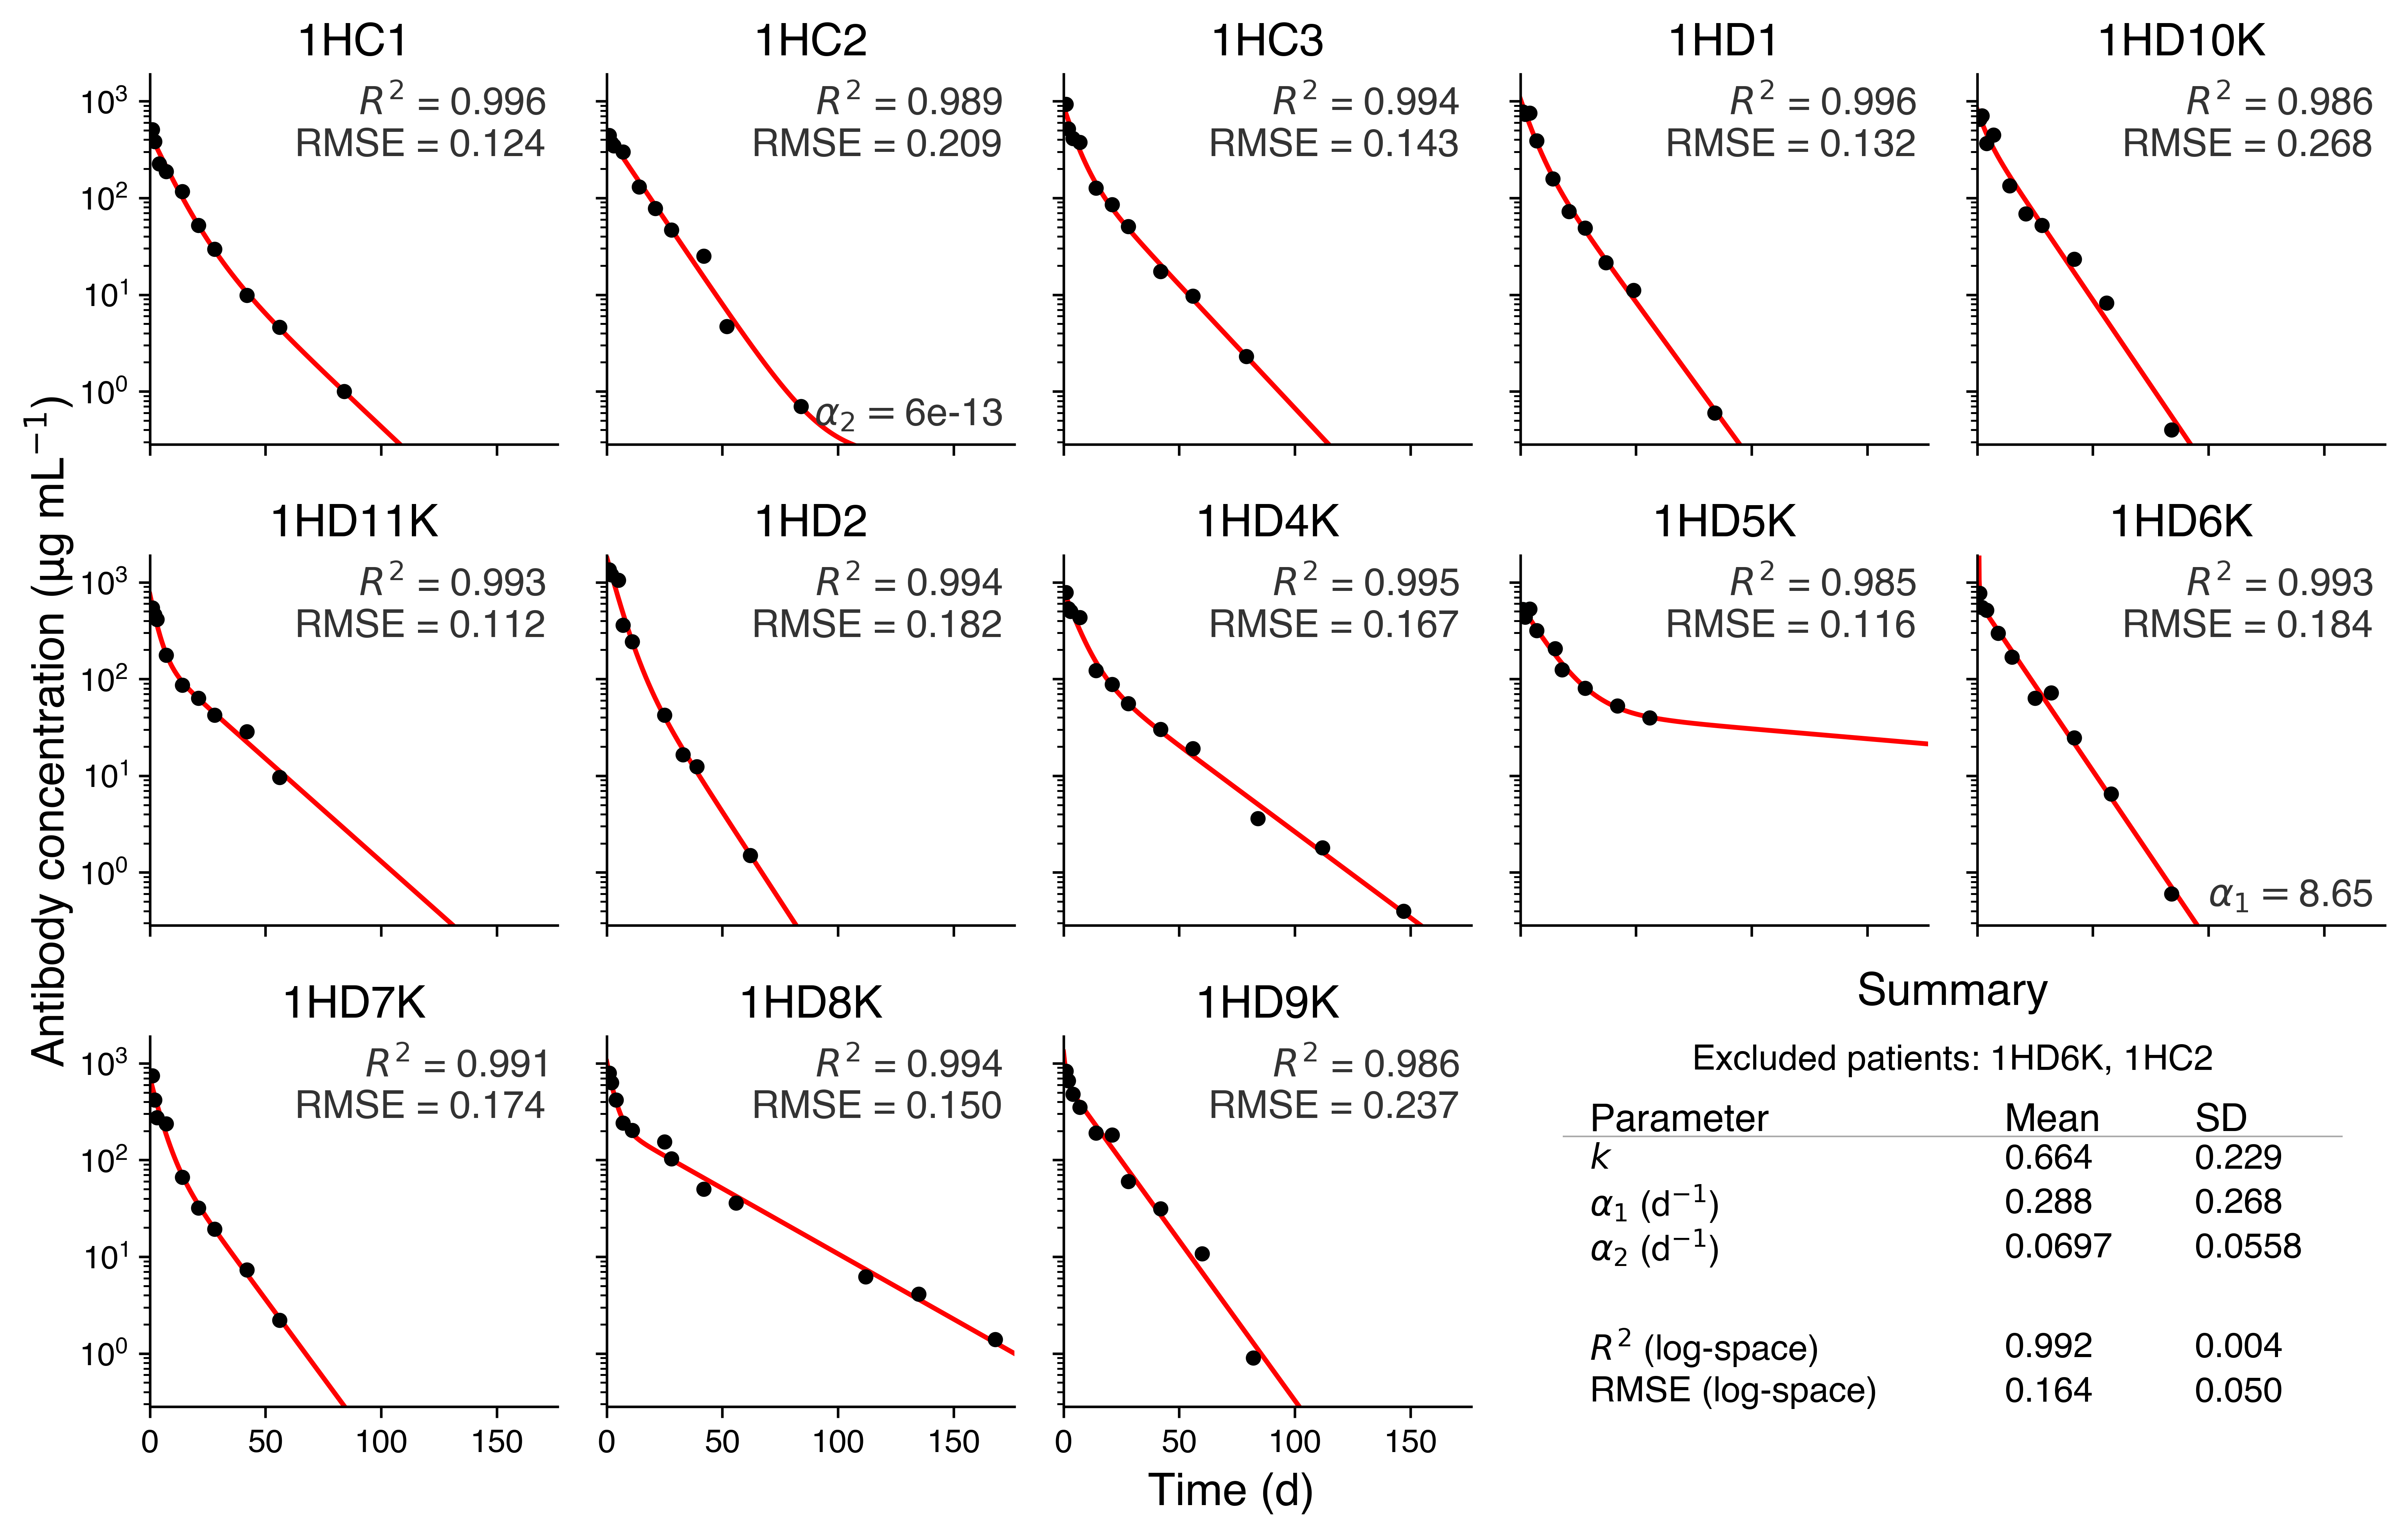

In [2]:
## Generate Fig. S2: pharmacokinetic data fitting
#Supplementary figure 5 - fitting patient data
#Data are the serum antibody concentrations for 13 patients treated with 30 mg/kg 10-1074
#From supplementary table 3 in Caskey et al. (2017) - https://doi.org/10.1038/nm.4268

def biphasic_decay(t, Abmax, k, a1, a2):
    return Abmax * (k * np.exp(-a1 * t) + (1 - k) * np.exp(-a2 * t))

def biphasic_decay_log(t, Abmax, k, a1, a2):
    return np.log(Abmax * (k * np.exp(-a1 * t) + (1 - k) * np.exp(-a2 * t)))

#Fit biphasic decay parameters
def fit_patient(df_patient):
    times = df_patient["Time"].values
    Ab = df_patient["Concentration"].values
    
    Abmax0 = Ab.max()
    k0 = 0.5
    a1_0 = 0.5
    a2_0 = 0.05

    lower = [0, 0, 0, 0]
    upper = [np.inf, 1, np.inf, np.inf]

    popt, pcov = curve_fit(
        biphasic_decay_log,
        times,
        np.log(Ab),
        p0=[Abmax0, k0, a1_0, a2_0],
        bounds=(lower, upper),
        method='trf',
        maxfev=250000
    )
    
    return popt

def compute_fit_metrics(times, Ab, par):
    Abmax, k, a1, a2 = par
    pred = biphasic_decay(times, Abmax, k, a1, a2)
    log_resid = np.log(Ab) - np.log(pred)
    RMSE = np.sqrt(np.mean(log_resid**2))
    ss_res_log = np.sum(log_resid**2)
    ss_tot_log = np.sum((np.log(Ab) - np.log(Ab).mean())**2)
    R2 = 1.0 - ss_res_log / ss_tot_log

    return {"R2": R2, "RMSE": RMSE}

def fit_all_patients(df):
    results = []
    for patient, dfp in df.groupby("Patient"):
        par = fit_patient(dfp)
        metrics = compute_fit_metrics(dfp["Time"].values, dfp["Concentration"].values, par)
        results.append({
            "Patient": patient,
            "Abmax": par[0],
            "k": par[1],
            "a1": par[2],
            "a2": par[3],
            **metrics
        })
    return pd.DataFrame(results)

def _global_axes_limits(df, results_df):
    t_max  = df["Time"].max()
    Ab_min = df["Concentration"].min()
    Ab_max = df["Concentration"].max()
    log_margin = 0.15
    y_lo = 10 ** (np.log10(Ab_min) - log_margin)
    y_hi = 10 ** (np.log10(Ab_max) + log_margin)
    x_hi = t_max * 1.05
 
    return (0, x_hi), (y_lo, y_hi)

def _summary_stats(results_df, exclude):
    """Return a dict of mean ± SD for key parameters."""
    cols = ["k", "a1", "a2", "R2", "RMSE"]
    stats = {}
    for c in cols:
        stats[c] = (results_df[~results_df['Patient'].isin(exclude)][c].mean(), results_df[~results_df['Patient'].isin(exclude)][c].std())
    return stats

def _draw_summary_panel(ax, results_df, exclude):
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_xticks([])
    ax.set_yticks([])

    stats = _summary_stats(results_df, exclude)
    label_map = {
        "k": (r"$k$", "{:.3f}"),
        "a1": (r"$\alpha_1$ (d$^{-1}$)", "{:.3f}"),
        "a2": (r"$\alpha_2$ (d$^{-1}$)", "{:.4f}"),
        "R2": (r"$R^2$ (log-space)", "{:.3f}"),
        "RMSE": (r"RMSE (log-space)", "{:.3f}"),
    }

    rows = []
    for key in ["k", "a1", "a2", "R2", "RMSE"]:
        mean, sd = stats[key]
        lbl, fmt = label_map[key]
        rows.append((lbl, fmt.format(mean), fmt.format(sd)))

        if key == "a2":
            rows.append(("spacer", "", ""))

    col_x = [0.08, 0.56, 0.78]
    col_headers = ["Parameter", "Mean", "SD"]

    ax.set_title("Summary", fontsize=14, fontweight="bold", pad=10)

    excluded_text = "Excluded patients: " + ", ".join(exclude)
    ax.text(0.5, 0.98, excluded_text, transform=ax.transAxes, ha="center", va="top", fontsize=11)

    #Header
    y = 0.82
    for cx, ch in zip(col_x, col_headers):
        ax.text(cx, y, ch, transform=ax.transAxes, ha="left", va="top", fontsize=12, color="k")
    ax.axhline(y=y - 0.09, xmin=0.05, xmax=0.95, color="#aaa", linewidth=0.5)

    #Rows
    row_h = 0.12
    y -= 0.11
    for lbl, mean_s, sd_s in rows:
        if lbl == "spacer":
            y -= 0.15
            continue

        ax.add_patch(mpatches.Rectangle((0.04, y - row_h * 0.85), 0.92, row_h * 0.9, transform=ax.transAxes, facecolor='white', edgecolor="none", zorder=0))
        for cx, val in zip(col_x, [lbl, mean_s, sd_s]):
            ax.text(cx, y - row_h * 0.35, val, transform=ax.transAxes, ha="left", va="center", fontsize=11)
        
        y -= row_h

df = pd.read_csv("../Simulation_data/10-1074_PK_data.csv")
results_df = fit_all_patients(df)
exclude = ['1HD6K', '1HC2']
patients = results_df["Patient"].tolist()
n_patients = len(patients)
n_slots = n_patients + 1
n_cols = 5
n_rows = int(np.ceil(n_slots / n_cols))
xlim, ylim = _global_axes_limits(df, results_df)

fig = plt.figure(figsize=(12.5, 7.5))
gs = GridSpec(3, 5, figure=fig, hspace=0.3, wspace=0.12)
axes = []
for idx, patient in enumerate(patients):
    row, col = divmod(idx, n_cols)
    ax = fig.add_subplot(gs[row, col])
    axes.append((ax, patient))

all_patient_axes = [ax for ax, _ in axes]

for ax, patient in axes:
    dfp = df[df["Patient"] == patient]
    par = results_df[results_df["Patient"] == patient].iloc[0]
    Abmax = par["Abmax"]
    k = par["k"]
    a1 = par["a1"]
    a2 = par["a2"]
    ax.scatter(dfp["Time"], dfp["Concentration"], s=14, color='k', zorder=3)

    t_fit  = np.linspace(0, xlim[1], 400)
    Ab_fit = biphasic_decay(t_fit, Abmax, k, a1, a2)
    ax.plot(t_fit, Ab_fit, color='red', zorder=2)
    ax.set_yscale("log")
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    ax.yaxis.set_major_locator(mticker.LogLocator(base=10, numticks=5))
    ax.yaxis.set_minor_locator(mticker.LogLocator(base=10, subs=np.arange(2, 10) * 0.1, numticks=10))

    r2_key   = "R2_log"  if "R2_log"   in par.index else "R2"
    rmse_key = "RMSE_log" if "RMSE_log" in par.index else "RMSE"
    r2_lbl   = r"$R^2_{\log}$" if r2_key == "R2_log" else r"$R^2$"
    metrics_str = (f"{r2_lbl} = {par[r2_key]:.3f}\n"
                   f"RMSE = {par[rmse_key]:.3f}")
    ax.text(0.97, 0.97, metrics_str, transform=ax.transAxes, ha="right", va="top", fontsize=12, color="#333")
    if patient == "1HD6K":
        ax.text(0.97, 0.03, r"$\alpha_1=$"+f"{a1:.2f}", transform=ax.transAxes, ha="right", va="bottom", fontsize=12, color="#333")
    elif patient == "1HC2":
        ax.text(0.97, 0.03, r"$\alpha_2=$"+f"{a2:.0e}", transform=ax.transAxes, ha="right", va="bottom", fontsize=12, color="#333")

    ax.set_title(f"{patient}", fontsize=14)


ax_sum = fig.add_subplot(gs[2, 3:5])
_draw_summary_panel(ax_sum, results_df, exclude)

last_row = max(i // n_cols for i in range(n_patients))
for ax, patient in axes:
    col_idx = patients.index(patient) % n_cols
    row_idx = patients.index(patient) // n_cols
    if col_idx != 0:
        ax.set_yticklabels([])
    if row_idx != last_row:
        ax.set_xticklabels([])

fig.text(0.5, 0.06, "Time (d)", ha="center", va="center", fontsize=14)
fig.text(0.09, 0.5, "Antibody concentration (μg mL$^{-1}$)",
         ha="center", va="center", rotation="vertical", fontsize=14)

plt.savefig('FigS2.png', dpi=600, bbox_inches='tight')

## Antibody response plotting functions

### Drawing antibody concentration and load and viral load panels across administration times

In [3]:
def format_dose(dose):
    return f"{dose:.1e}".replace(".", "p")

def plot_antibody_concentration_panel(ax, dose, decay_mode,
    base_dir='../Simulation_data/WT_Ab/',
    timepoints=(90, 180, 365, 540, 730), seed=1, show_legend=False, legend_kwargs=None,
    xlimits=(0, 900), ylimits=(1e-9, 5e-6), linewidth=2.4):

    if isinstance(timepoints, (int, float)):
        timepoints = [timepoints]
    
    if legend_kwargs is None:
        legend_kwargs = dict(loc="upper right", fontsize="small", frameon=False)

    palette = sns.husl_palette(len(timepoints), h=0.55, l=0.5)
    sim_dir = os.path.join(base_dir, f"sim_outputs_{decay_mode}")

    for i, tp in enumerate(timepoints):
        fname = os.path.join(sim_dir, f"totals_time{tp}_dose{format_dose(dose)}_seed{seed}.csv")
        df = pd.read_csv(fname)

        t = df['time'].to_numpy(dtype=float)
        ab_conc = df['Ab'].to_numpy(dtype=float)

        ax.plot(t, ab_conc, color=palette[i], linewidth=linewidth, label=f"t={tp}")

    ax.set_yscale("log")
    ax.set_xlim(xlimits)
    ax.set_ylim(ylimits)
    ax.set_xlabel("Time (d)")
    ax.set_ylabel("Antibody\nconcentration (M)")

    if show_legend:
        ax.legend(**legend_kwargs)

def plot_viral_load_panel(ax, dose, decay_mode,
    base_dir='../Simulation_data/WT_Ab/',
    timepoints=(90, 180, 365, 540, 730), seeds=[i for i in range(1, 11)], show_legend=False, legend_kwargs=None,
    ylimits=(1e-1, 3e5), xlimits=(0, 900), linewidth=2.4, shade_alpha=0.22, mode="shade", seed_alpha=0.65):
    
    if isinstance(timepoints, (int, float)):
        timepoints = [timepoints]
    if legend_kwargs is None:
        legend_kwargs = dict(loc="upper right", fontsize="small", frameon=False)
    
    palette = sns.husl_palette(len(timepoints), h=0.55, l=0.5)
    sim_dir = os.path.join(base_dir, f"sim_outputs_{decay_mode}")
    legend_handles = []
    legend_labels = []
    for i, tp in enumerate(timepoints):
        seed_series = []
        seed_times_list = []
        for seed in seeds:
            fname = os.path.join(sim_dir, f"totals_time{tp}_dose{format_dose(dose)}_seed{seed}.csv")
            df = pd.read_csv(fname)
            t = df['time'].to_numpy(dtype=float)
            v = df['sum_V'].to_numpy(dtype=float)
            
            #Zero out viral load if it drops below 1 virus particle
            extinct = np.where(v < 1)[0]
            if extinct.size > 0:
                v[extinct[0]:] = 0.0
            seed_times_list.append(t)
            seed_series.append(v)
        common_times = np.unique(np.concatenate(seed_times_list))
        common_times.sort()
        n_seeds_present = len(seed_series)
        values_on_grid = np.full((n_seeds_present, common_times.size), np.nan, dtype=float)
        for si, (t, v) in enumerate(zip(seed_times_list, seed_series)):
            tmin, tmax = t.min(), t.max()
            mask = (common_times >= tmin) & (common_times <= tmax)
            if mask.any():
                values_on_grid[si, mask] = np.interp(common_times[mask], t, v)
        with np.errstate(invalid="ignore"):
            mean_vals = np.nanmean(values_on_grid, axis=0)
            min_vals = np.nanmin(values_on_grid, axis=0)
            max_vals = np.nanmax(values_on_grid, axis=0)
        if mode == 'shade':
            ax.fill_between(common_times, min_vals/5000, max_vals/5000, color=palette[i], alpha=shade_alpha, linewidth=0)
            ax.plot(common_times, mean_vals/5000, color=palette[i], linewidth=linewidth, label=f"t={tp}", solid_capstyle='round')
        else:
            for si in range(n_seeds_present):
                row = values_on_grid[si]
                ax.plot(common_times, row/5000, color=palette[i], linewidth=linewidth*0.85, alpha=seed_alpha, solid_capstyle='round', zorder=1)
        legend_handles.append(None)
        legend_labels.append(f"t = {tp}")
    ax.set_yscale("log")
    ax.set_ylim(ylimits)
    ax.set_xlim(xlimits)
    ax.set_xlabel("Time (d)")
    ax.set_ylabel("Viral Load (mL$^{-1}$)")
    if show_legend:
        leg = ax.legend(**legend_kwargs)
    
    return ax

def r0_fun(ddg_receptor, ddg_ab, Ab_dose, p):
    ddg_receptor = np.asarray(ddg_receptor, dtype=float)
    mult = (1.0+p['h'])**p['K']
    ddg_receptor_transform = mult*(1.0/(1.0 + p['h']*np.exp(ddg_receptor / p['RT']))) ** p['K']
    ddg_ab = np.asarray(ddg_ab, dtype=float)
    Ab_dose = np.asarray(Ab_dose, dtype=float)
    return (p['beta_wt']*ddg_receptor_transform*p['lambda_T']*p['gamma']*p['n'])/(p['c']*p['d']*(p['delta1']+p['gamma'])*(1+((Ab_dose/p['KD_WT'])*np.exp(-ddg_ab/p['RT']))))

### Shared top-k plots pre- and post-Ab administration

In [4]:
def _integrated_V(topk_df):
    grp = topk_df.groupby(["sequence", "time"], as_index=False)["V"].sum()
    pivot = grp.pivot_table(index="sequence", columns="time", values="V", aggfunc="sum", fill_value=0.0)
    times = np.sort(pivot.columns.astype(float))
    pivot = pivot.reindex(columns=times, fill_value=0.0)
    areas = np.trapezoid(pivot.to_numpy(float), x=times, axis=1)
    return dict(zip(pivot.index, areas))

def compute_global_topk(topk_dfs, top_k=20):
    """Compute the global top-K sequences across runs by summing integrated viral loads per variant."""
    
    totals = {}
    for df in topk_dfs:
        for seq, area in _integrated_V(df).items():
            totals[seq] = totals.get(seq, 0.0) + area
    return [s for s, _ in sorted(totals.items(), key=lambda x: x[1], reverse=True)[:top_k]]

def build_color_map(global_seqs, wt_seq='DIRQH', wt_slot=0, palette="tab20"):
    """Build a sequence -> color mapping for a set of viral sequences.
    Give the wild type a specific color in the palette."""
    tab20 = sns.color_palette(palette, 20)
    wt_rgb = to_rgb(tab20[wt_slot % 20])
    pool = [to_rgb(c) for i, c in enumerate(tab20) if i != wt_slot % 20]

    cmap: dict = {}
    if wt_seq in global_seqs:
        cmap[wt_seq] = wt_rgb

    pi = 0
    for s in global_seqs:
        if s not in cmap:
            cmap[s] = pool[pi % len(pool)]
            pi += 1

    cmap["__others__"] = "#ebebebf2"
    return cmap

def _build_pivot(topk_df, times):
    grp = topk_df.groupby(["sequence", "time"], as_index=False)["V"].sum()
    pivot = grp.pivot_table(index="sequence", columns="time", values="V", aggfunc="sum", fill_value=0.0)
    return pivot.reindex(columns=times, fill_value=0.0)

def _freq_matrix(pivot, sequences, totals_ts):
    rows = [pivot.loc[s].to_numpy(float) if s in pivot.index else np.zeros(pivot.shape[1]) for s in sequences]
    arr = np.vstack(rows) if rows else np.zeros((1, pivot.shape[1]))

    with np.errstate(divide="ignore", invalid="ignore"):
        freqs = np.divide(arr, totals_ts[np.newaxis, :], where=totals_ts > 0)
        freqs[:, totals_ts == 0] = 0.0

    others = np.clip(1.0 - freqs.sum(axis=0), 0.0, 1.0)
    return np.vstack([freqs, others])

def _shade_below_vl(ax, times, totals_ts, threshold=1, color="#4a4a4a", y_top=1.0, y_bottom=-1.0):
    low = totals_ts < threshold
    if not low.any():
        return
    pad = np.r_[0, low.view(np.int8), 0]
    diffs = np.diff(pad)
    for s_idx, e_idx in zip(np.where(diffs == 1)[0], np.where(diffs == -1)[0]):
        t_seg = times[s_idx - 1: e_idx]
        if t_seg.size:
            ax.fill_between(t_seg, y_bottom, y_top, color=color, alpha=1.0,
                            linewidth=0, zorder=10)

def stacked_frequency_plot(ax, totals_df, topk_df, sequences, color_map, classification=None,
                            x_max=365, wt_seq='DIRQH', vl_mode=False, wt_legend=False, y_floor=-1):
    """Plot the frequencies of the top-K variants over time in a simulation.
    Optionally takes in a variant classification for labeling core/accessory/unique variants from multiple simulations.
    If vl_mode=TRUE, the VL curve is plotted and abundances on a log scale are shown underneath this curve."""
    times = np.sort(totals_df["time"].unique())
    totals_ts = totals_df.set_index("time").reindex(times)["sum_V"].fillna(0.0).to_numpy(float)
    n_seqs = len(sequences)
    pivot = _build_pivot(topk_df, times)
    freq_mat = _freq_matrix(pivot, sequences, totals_ts)

    if vl_mode:
        log_vl = np.where(totals_ts > 0, np.log10(totals_ts / 5000), np.nan)
        above_threshold = totals_ts >= 0.01
        log_vl_clipped = np.where(above_threshold, log_vl, np.nan)
        span = log_vl_clipped - y_floor
        weights = np.where(span > 0, span, np.nan)
        y_max = np.log10(3e5)
    else:
        weights = np.ones(len(times))
        y_max = 1.0

    stack = freq_mat * weights[np.newaxis, :]
    cum = np.nancumsum(stack, axis=0) if vl_mode else np.cumsum(stack, axis=0)
    base = y_floor if vl_mode else 0.0
    bottoms = np.vstack([np.full(len(times), base), base + cum[:-1]])

    def _bot_top(i):
        return bottoms[i], bottoms[i] + stack[i]

    labels = sequences + ["__others__"]
    for i, lbl in enumerate(labels):
        color = color_map.get(lbl, color_map["__others__"])
        bot_i, top_i = _bot_top(i)
        ax.fill_between(times, bot_i, top_i, facecolor=color, linewidth=0)
        #Hatching for accessory/unique sequences
        if i < n_seqs and classification and lbl in classification:
            cat = classification[lbl]
            hatch = ("////" if cat == "accessory" else "xxxx" if cat == "unique" else None)
            if hatch:
                ax.fill_between(times, bot_i, top_i, facecolor="none", edgecolor="white", linewidth=0, hatch=hatch, alpha=0.5)

    _shade_below_vl(ax, times, totals_ts, y_top=y_max)
    ax.set_xlim(times.min(), x_max)

    if vl_mode:
        ax.plot(times, log_vl, color="black", lw=1.5, zorder=8)
        y_ceil = int(np.ceil(y_max))
        ticks = list(range(y_floor, y_ceil + 1))
        ax.set_yticks(ticks)
        ax.set_yticklabels([f"$10^{{{t}}}$" for t in ticks])
        ax.set_ylim(y_floor, y_max)
        ax.set_ylabel("Viral Load (mL$^{-1}$)")
    else:
        ax.set_ylim(0, 1)
        ax.set_ylabel("Frequency")

    if wt_legend and wt_seq in sequences:
        ax.legend(handles=[mpatches.Patch(color=color_map[wt_seq], label=f"Wild type ({wt_seq})")], bbox_to_anchor=(0.5, 1.18), loc="upper center", frameon=False)

def compute_shared_after_topk(topk_dfs_after, global_seqs, top_k_after=10, global_color_map=None, after_palette="tab20b"):
    """Compute a global post-Ab top-K and generate a new colormap combining the global colormap with the new top-K."""
    
    after_seqs_all = compute_global_topk(topk_dfs_after, top_k=top_k_after)
    new_after_seqs = [s for s in after_seqs_all if s not in global_seqs]

    pool_after = [to_rgb(c) for c in sns.color_palette(after_palette, top_k_after)]
    after_color_map = {}
    i = 0
    for s in new_after_seqs:
        after_color_map[s] = pool_after[i % len(pool_after)]
        i += 1

    return new_after_seqs, after_color_map

def build_pre_post_topk_plot(ax, totals_df, topk_df, ab_time, global_seqs, global_color_map,
                             new_after_seqs, after_color_map, pre_window=10, post_window=50, wt_seq='DIRQH',
                             vl_mode=False, wt_legend=False, x_max=None, ab_line_color="black", title=None, titlecolor='k', ab_time2=None):
    """Plot a stacked frequency plot spanning pre- and post-antibody administration with unique color palettes for before and after administration."""
    
    t_start = ab_time - pre_window
    t_end = ab_time + post_window

    totals_win = totals_df[(totals_df["time"] >= t_start) & (totals_df["time"] <= t_end)]
    topk_win = topk_df[(topk_df["time"] >= t_start) & (topk_df["time"] <= t_end)]

    sequences = list(global_seqs) + list(new_after_seqs)

    color_map = dict(global_color_map)
    color_map.update(after_color_map)
    color_map.setdefault("__others__", "#ebebebf2")

    if x_max is None:
        x_max = t_end

    stacked_frequency_plot(ax, totals_win, topk_win, sequences, color_map, x_max=x_max, wt_seq=wt_seq, vl_mode=vl_mode, wt_legend=wt_legend)
    ax.set_title(title, color=titlecolor, fontsize=12)
    ax.axvline(ab_time, color=ab_line_color, lw=1, ls="--", zorder=9)

    if ab_time2:
        ax.axvline(ab_time2, color=ab_line_color, lw=1, ls="--", zorder=9)

### ddG landscape and trajectory overlays

In [5]:
def plot_ddg_landscape(ax, df, params, dose, ddg_col='ddG', ddg_ab_col='ddG_Ab', contour_levels=[1],
                        wt_seq="DIRQH", bins=60, show_colorbar=False, cax=None, show_R0_no_Ab_contour=False):
    if "sequence" not in df.columns:
        df = df.copy()
        df["sequence"] = df.iloc[:, :5].astype(str).agg(''.join, axis=1)
    xs = df[ddg_col].values
    ys = df[ddg_ab_col].values
    r0_vals = np.asarray(r0_fun(xs, ys, dose, params), dtype=float)
    fig = ax.figure
    #Make histogram background based on abundance
    H, xedges, yedges = np.histogram2d(xs, ys, bins=bins)
    H_log = np.log10(H + 1)
    vmin = 0
    vmax = np.log10(H.max() + 1)
    mesh = ax.pcolormesh(xedges, yedges, H_log.T, cmap="Greys", shading="auto", vmin=vmin, vmax=vmax, zorder=1)
    #Plot R0 > 1 variants
    mask = r0_vals > 1
    ax.scatter(xs[mask], ys[mask], c='orangered', s=25, alpha=0.2, edgecolor="none", zorder=5)
    #Mark WT sequence
    wt_row = df.loc[df["sequence"] == wt_seq].iloc[0]
    ax.scatter(wt_row[ddg_col], wt_row[ddg_ab_col], s=150, marker="*", edgecolor="white", linewidth=0.9, color="black", zorder=5)

    #Add contours
    xpad = max(0.5, 0.05 * (xs.max() - xs.min()))
    ypad = max(0.5, 0.05 * (ys.max() - ys.min()))
    xgrid = np.linspace(xs.min() - xpad, xs.max() + xpad, 300)
    ygrid = np.linspace(ys.min() - ypad, ys.max() + ypad, 300)
    X, Y = np.meshgrid(xgrid, ygrid)
    Z = r0_fun(X, Y, dose, params)
    cs = ax.contour(X, Y, Z, levels=contour_levels, colors='black', linewidths=1.5, zorder=4)
    if show_R0_no_Ab_contour:
        Z_no_Ab = r0_fun(X, Y, 0, params)
        cs2 = ax.contour(X, Y, Z_no_Ab, levels=[1], colors='red', linewidths=1.5, linestyles='dashed', zorder=4)
    xmax, xmin = X.max(), X.min()
    ymax, ymin = Y.max(), Y.min()
    xspan = xmax - xmin
    yspan = ymax - ymin

    label_positions = []
    for i, level in enumerate(cs.levels):
        segs = cs.allsegs[i]
        seg_max_y = [seg[:, 1].max() for seg in segs]
        seg_idx = int(np.argmax(seg_max_y))
        segment = segs[seg_idx]
        idx_top = int(np.argmax(segment[:, 1]))
        vx, vy = segment[idx_top]
        offset_y = -0.1 * yspan
        vx_label = vx
        vy_label = vy + offset_y - 0.065 * yspan
        vx_label = np.clip(vx_label, xmin + 0.01 * xspan, xmax - 0.01 * xspan)
        vy_label = np.clip(vy_label, ymin + 0.01 * yspan, ymax - 0.01 * yspan)

        label_positions.append((vx_label, vy_label))

    ax.set_xlabel(r"$\Delta\Delta G_{receptor}$")
    ax.set_ylabel(r"$\Delta\Delta G_{antibody}$")
    if show_colorbar:
        cb = fig.colorbar(mesh, cax=cax)
        linear_ticks = np.array([10**1, 10**2, 10**3, 10**4])
        log_ticks = np.log10(linear_ticks)

        cb.set_ticks(log_ticks)
        labs = [rf"$10^{{{int(np.log10(t))}}}$" for t in linear_ticks]

        cb.set_ticklabels(labs)
        cb.ax.yaxis.set_ticks_position('left')
        cb.ax.yaxis.set_label_position('left')
        cb.set_label("Number of variants")
    return ax.figure, ax

def compute_weighted_centroid(topk_df, df, time_value, ddg_col="ddG", ddg_ab_col="ddG_Ab"):
    """Abundance-weighted centroid (ddG, ddG_Ab) at nearest time point from top-K file."""

    times = topk_df["time"].to_numpy()
    nearest_time = times[np.abs(times - time_value).argmin()]
    snap = (topk_df[topk_df["time"] == nearest_time].groupby("sequence", as_index=False)["V"].sum())

    merged = snap.merge(df[["sequence", ddg_col, ddg_ab_col]], on="sequence", how="inner")
    w = merged["V"].to_numpy()
    cx = np.average(merged[ddg_col], weights=w)
    cy = np.average(merged[ddg_ab_col], weights=w)

    return cx, cy

def draw_population_trajectory(ax, topk_df, df, ab_time, pre_offset=0, post_offset=0,
                                ddg_col='ddG', ddg_ab_col='ddG_Ab', color="purple",
                                arrow_lw=1.5, head_width=0.1, head_length=0.2, zorder=7):
    """Draw an arrow from the pre-Ab centroid to the post-Ab centroid."""
    
    pre_time = ab_time + pre_offset
    post_time = ab_time + post_offset

    start = compute_weighted_centroid(topk_df[topk_df["time"] < ab_time], df, pre_time, ddg_col=ddg_col, ddg_ab_col=ddg_ab_col)
    end = compute_weighted_centroid(topk_df[topk_df["time"] >= ab_time], df, post_time, ddg_col=ddg_col, ddg_ab_col=ddg_ab_col)

    ax.annotate("", xy=end, xytext=start, arrowprops=dict(arrowstyle="->", color=color, lw=arrow_lw, mutation_scale=18), zorder=zorder)
    ax.scatter([start[0]], [start[1]], s=25, facecolor='white', edgecolor=color, linewidth=1.5, zorder=zorder, marker="o")

### Distribution of Hamming distances to nearest escape mutant with R0>X

In [6]:
def get_topk_at_time(topk_df, time_value, top_k=20):
    times = topk_df["time"].unique()
    nearest = times[np.argmin(np.abs(times - time_value))]
    snap = topk_df[topk_df["time"] == nearest]
    agg = snap.groupby("sequence", as_index=False)["V"].sum()
    agg = agg.sort_values("V", ascending=False)
    return list(agg["sequence"].head(top_k))

def hamming_dist(a, b):
    return sum(x != y for x, y in zip(a, b))

def min_hamming_to_set(seq, target_seqs):
    """Minimum Hamming distance from seq to any sequence in target_seqs."""
    if not target_seqs:
        return None
    return min(hamming_dist(seq, t) for t in target_seqs)

def get_escape_seqs(df, params, dose, ddg_col='ddG', ddg_ab_col='ddG_Ab', ddg_threshold=1):
    """Return the set of sequences with R0 > threshold at given antibody dose."""
    xs = df[ddg_col].values
    ys = df[ddg_ab_col].values
    r0_vals = np.asarray(r0_fun(xs, ys, dose, params), dtype=float)
    return set(df.loc[r0_vals > ddg_threshold, "sequence"])

def plot_min_hamming_histogram(ax, topk_df, ab_time, escape_seqs, top_k_pre=20, color="k"):
    """Histogram of minimum Hamming distance from each pre-Ab top-K sequence present at
    the antibody administation time to the nearest sequence in the post-Ab top-K."""
    
    pre_seqs = get_topk_at_time(topk_df[topk_df["time"] < ab_time], ab_time, top_k=top_k_pre)
    dists = [min_hamming_to_set(s, escape_seqs) for s in pre_seqs]
    dists = [d for d in dists if d is not None]
    bins = np.arange(-0.5, 4+1.5, 1)
    ax.hist(dists, bins=bins, color=color, edgecolor="white", linewidth=0.8, density=True)

def plot_min_hamming_histogram_compare(ax, topk_df, ab_time, escape_seqs_a, escape_seqs_b,
                                label_a=f"$R_0>1$", label_b=f"$R_0>0.25$",
                                top_k_pre=20, color="k",
                                hatch_a=None, hatch_b="///",
                                alpha=0.55, legend=True):
    pre_seqs = get_topk_at_time(topk_df[topk_df["time"] < ab_time], ab_time, top_k=top_k_pre)
    bins = np.arange(-0.5, 4 + 1.5, 1)
    
    dists_a = [min_hamming_to_set(s, escape_seqs_a) for s in pre_seqs]
    dists_a = [d for d in dists_a if d is not None]
    if dists_a:
        ax.hist(dists_a, bins=bins, color=color, density=True, alpha=0.75, hatch=hatch_a, label=label_a, zorder=2)
    dists_b = [min_hamming_to_set(s, escape_seqs_b) for s in pre_seqs]
    dists_b = [d for d in dists_b if d is not None]
    if dists_b:
        ax.hist(dists_b, bins=bins, color=color, linewidth=1.4, density=True, alpha=alpha, hatch=hatch_b, label=label_b, zorder=3, histtype='step')

    if legend:
        ax.legend(frameon=False, fontsize=9, loc="upper center")

## Generate Fig. 2: overview of dynamics after wild-type antibody administration

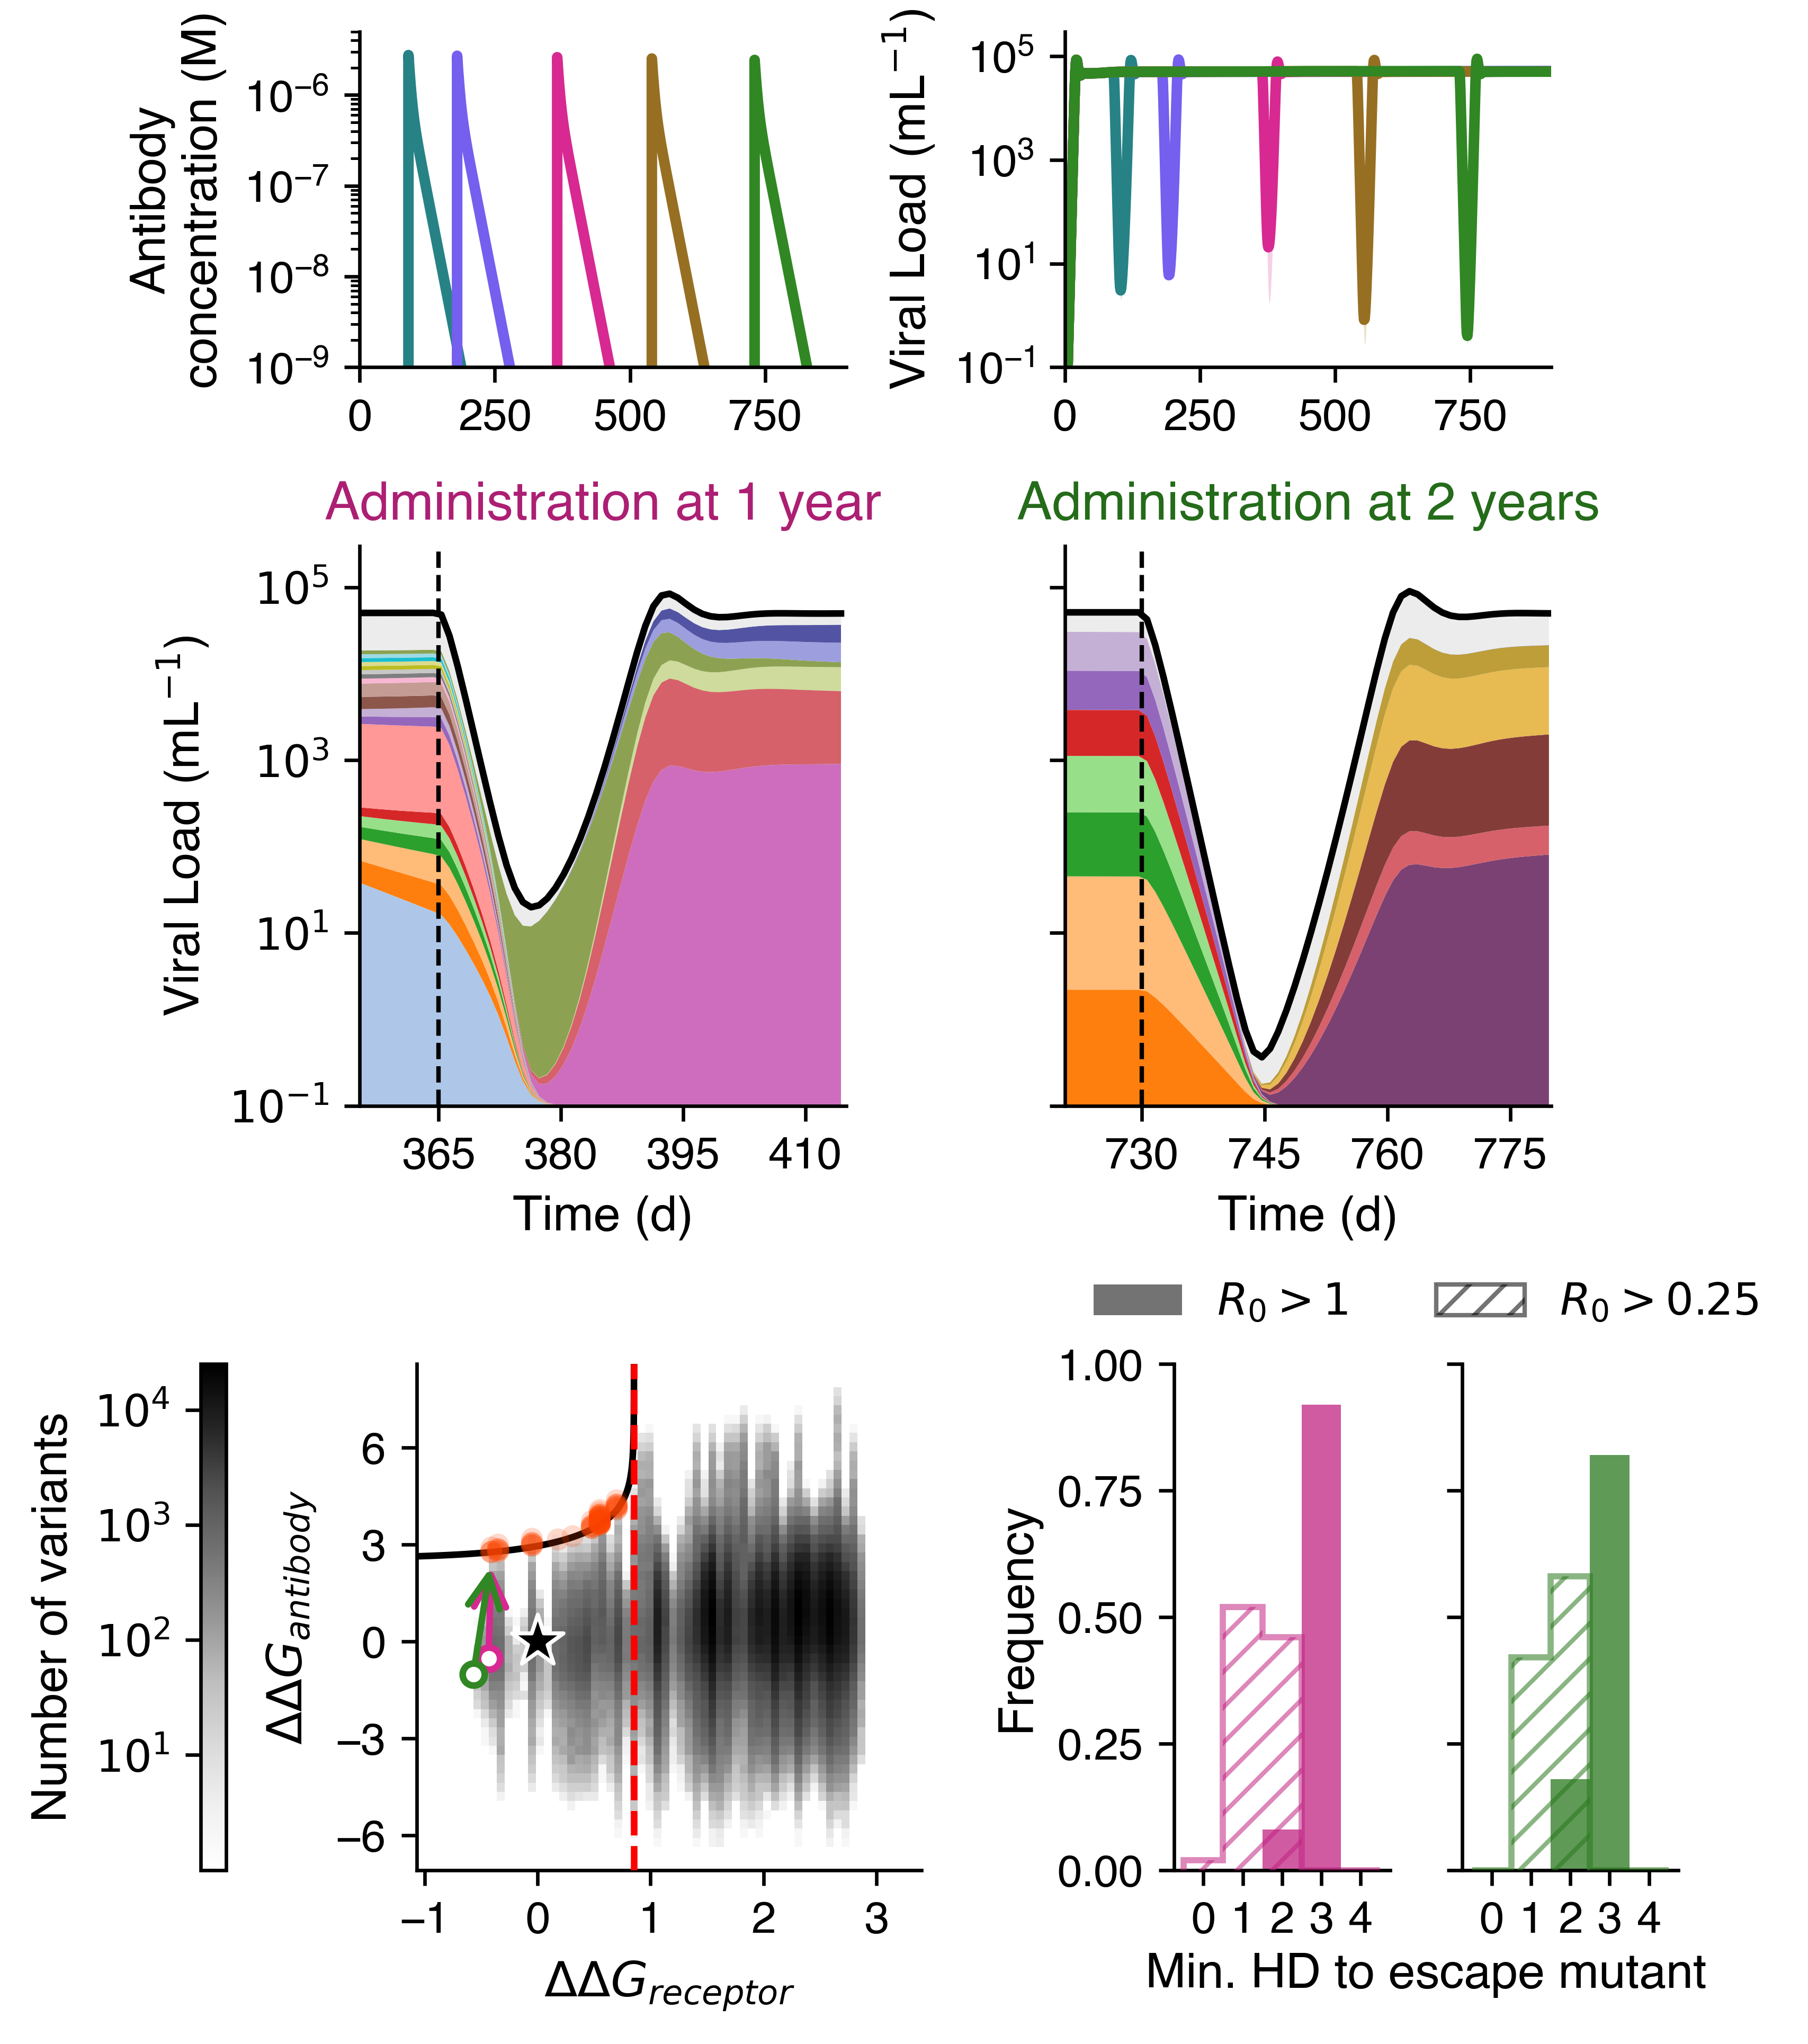

In [7]:
fig = plt.figure(figsize=(5, 6.5))
gs_top = fig.add_gridspec(nrows=2, ncols=2, wspace=0.45, hspace=0.4, height_ratios=[0.6, 1], left=0.15, right=0.90, top=0.97, bottom=0.45)
ax1 = fig.add_subplot(gs_top[0, 0])
ax2 = fig.add_subplot(gs_top[0, 1])
ax3 = fig.add_subplot(gs_top[1, 0])
ax4 = fig.add_subplot(gs_top[1, 1])

gs_bottom = fig.add_gridspec(nrows=1, ncols=1, left=0.05, right=0.98, top=0.325, bottom=0.08)
bottom = gs_bottom[0, 0].subgridspec(1, 5, width_ratios=[2, 0.7, 0.6, 0.2, 0.6], wspace=0)
ax5 = fig.add_subplot(bottom[0, 0])
ax6 = fig.add_subplot(bottom[0, 2])
ax7 = fig.add_subplot(bottom[0, 4])

#Panels 2A and 2B: antibody concentrations and viral loads
ddG_dataframe = pd.read_csv('../EvoEF_predictions/predictions_WT_Ab.csv', index_col=0)
plot_antibody_concentration_panel(ax1, 2.8e-6, 'biphasic')
plot_viral_load_panel(ax2, 2.8e-6, 'biphasic')
ax1.set_xlabel("")
ax1.set_xticks([0, 250, 500, 750])
ax2.set_xlabel("")
ax2.set_xticks([0, 250, 500, 750])

#Panels 2C and 2D: frequency plots after antibody administration 
base_dir = "../Simulation_data/No_Ab/sim_outputs"
example_totals = pd.read_csv(base_dir+'/totals_noAb_seed8.csv')
example_topk = pd.read_csv(base_dir+'/topk_noAb_seed8.csv')
topk_seqs = compute_global_topk([example_topk])
ex_colmap = build_color_map(topk_seqs)

base_dir = "../Simulation_data/WT_Ab/sim_outputs_biphasic"
totals_admin365 = pd.read_csv(base_dir+'/totals_time365_dose2p8e-06_seed8.csv')
topk_admin365 = pd.read_csv(base_dir+'/topk_time365_dose2p8e-06_seed8.csv')
totals_admin730 = pd.read_csv(base_dir+'/totals_time730_dose2p8e-06_seed8.csv')
topk_admin730 = pd.read_csv(base_dir+'/topk_time730_dose2p8e-06_seed8.csv')

new_after_seqs, after_color_map = compute_shared_after_topk([topk_admin365[topk_admin365["time"].between(365, 415)], topk_admin730[topk_admin730["time"].between(730, 780)]], topk_seqs, top_k_after=10, after_palette="tab20b_r", global_color_map=ex_colmap)
build_pre_post_topk_plot(ax3, totals_admin365, topk_admin365, 365, topk_seqs, ex_colmap, new_after_seqs, after_color_map, vl_mode=True, title="Administration at 1 year", titlecolor=sns.husl_palette(5, h=0.55, l=0.4)[2])
build_pre_post_topk_plot(ax4, totals_admin730, topk_admin730, 730, topk_seqs, ex_colmap, new_after_seqs, after_color_map, vl_mode=True, title="Administration at 2 years", titlecolor=sns.husl_palette(5, h=0.55, l=0.4)[4])
ax3.set_xlabel("Time (d)")
ax3.set_xticks([365, 380, 395, 410])
ax4.set_xlabel("Time (d)")
ax4.set_xticks([730, 745, 760, 775])
ax3.set_yticks([-1, 1, 3, 5])
ax4.set_yticks([-1, 1, 3, 5])
ax4.set_ylabel("")
ax4.set_yticklabels("")

#Panel 2E: ddG landscape with R0 contours
from mpl_toolkits.axes_grid1 import make_axes_locatable
divider = make_axes_locatable(ax5)
cax5 = divider.append_axes("left", size="5%", pad=0.6)
plot_ddg_landscape(ax5, ddG_dataframe, params, 2.8e-6, show_colorbar=True, show_R0_no_Ab_contour=True, bins=50, cax=cax5)
ax5.set_xticks([-1, 0, 1, 2, 3])
ax5.set_yticks([-6, -3, 0, 3, 6])
draw_population_trajectory(ax5, topk_admin365, ddG_dataframe, ab_time=365, pre_offset=-1, post_offset=50, color=sns.husl_palette(5, h=0.55, l=0.5)[2])
draw_population_trajectory(ax5, topk_admin730, ddG_dataframe, ab_time=730, pre_offset=-1, post_offset=50, color=sns.husl_palette(5, h=0.55, l=0.5)[4])

#Panel 2F: Hamming distances to escape mutants
escape_seqs_R0_1 = get_escape_seqs(ddG_dataframe, params, 2.8e-6, ddg_threshold=1)
escape_seqs_R0_0p25 = get_escape_seqs(ddG_dataframe, params, 2.8e-6, ddg_threshold=0.25)

plot_min_hamming_histogram_compare(ax6, topk_admin365, 365, escape_seqs_R0_1, escape_seqs_R0_0p25, top_k_pre=50, color=sns.husl_palette(5, h=0.55, l=0.45)[2], legend=False)
plot_min_hamming_histogram_compare(ax7, topk_admin730, 730, escape_seqs_R0_1, escape_seqs_R0_0p25, top_k_pre=50, color=sns.husl_palette(5, h=0.55, l=0.45)[4], legend=False)
ax6.set_xticks([0,1,2,3,4])
ax7.set_xticks([0,1,2,3,4])
ax6.set_yticks([0, 0.25, 0.5, 0.75, 1])
ax7.set_yticks([0, 0.25, 0.5, 0.75, 1])
ax7.set_yticklabels("")
ax6.set_ylabel("Frequency")
posax6 = ax6.get_position()
posax7 = ax7.get_position()
x_center = (posax6.x0 + posax7.x1) / 2
y_bottom = min(posax6.y0, posax7.y0)
y_top = max(posax6.y1, posax7.y1)
fig.text(x_center, y_bottom - 0.04, "Min. HD to escape mutant", ha="center", va="top")
handles = [mpatches.Patch(facecolor="black", alpha=0.55, label=f"$R_0>1$"), mpatches.Patch(facecolor="white", edgecolor="black", alpha=0.55, hatch="///", label=f"$R_0>0.25$"),]
fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(x_center, y_top), bbox_transform=fig.transFigure, ncol=2, frameon=False, fontsize=10)

plt.savefig('Fig2.png', dpi=600, bbox_inches='tight')

## Generate Fig. S3: viral loads with constant antibody concentration

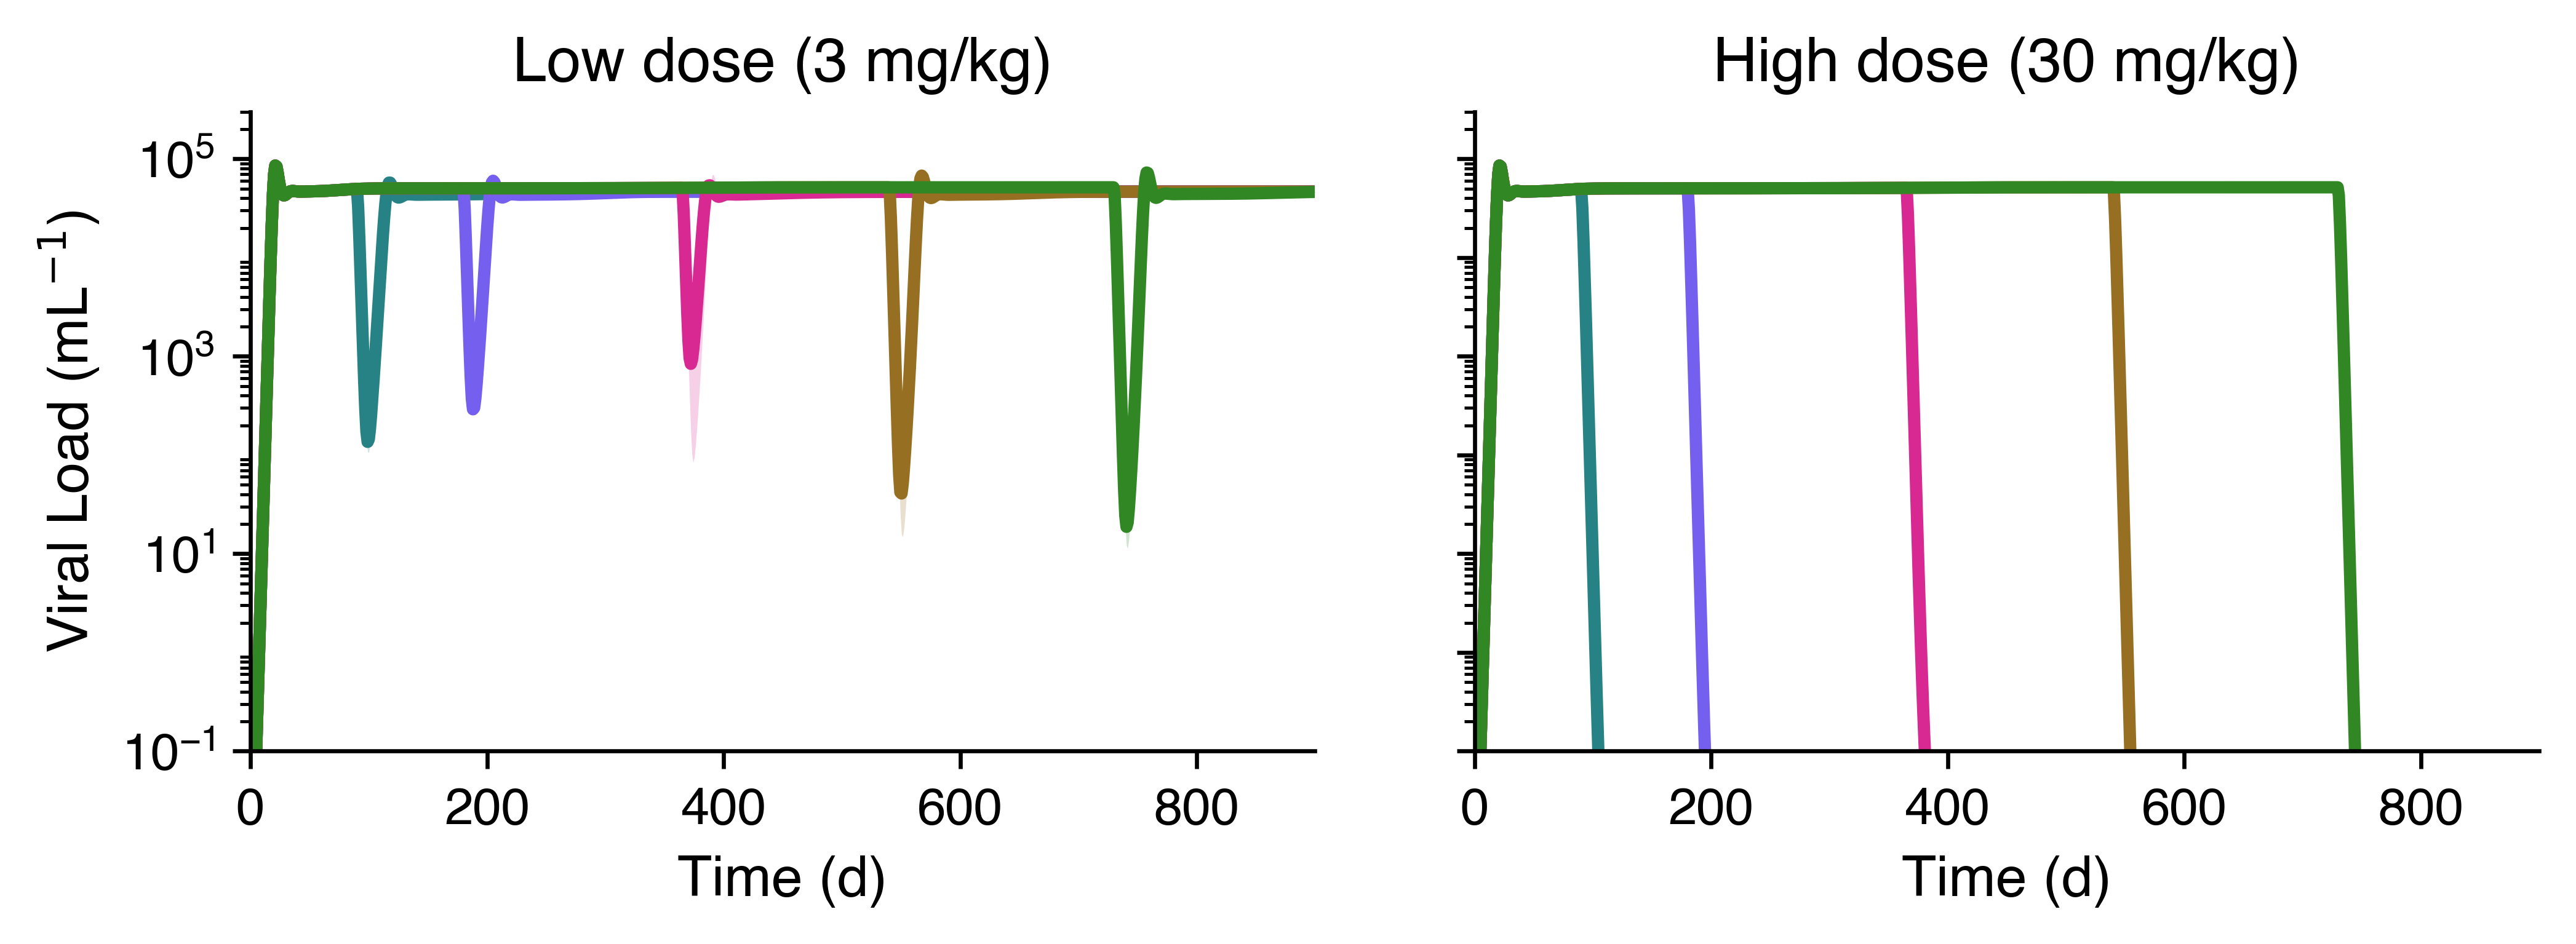

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 2.25), constrained_layout=False)
fig.subplots_adjust(wspace=0.15)

plot_viral_load_panel(ax1, 2.8e-7, 'constant')
plot_viral_load_panel(ax2, 2.8e-6, 'constant')
ax1.set_yticks([10**-1, 10**1, 10**3, 10**5])
ax2.set_ylabel("")
ax2.set_yticklabels("")
ax1.set_title("Low dose (3 mg/kg)", fontsize=12)
ax2.set_title("High dose (30 mg/kg)", fontsize=12)

plt.savefig('FigS3.png', dpi=600, bbox_inches='tight')

## Generate Fig. 3: visualizing the quasispecies response to antibody treatment

In [9]:
_STEM_RE = re.compile(r"totals"
    r"_time(?P<ab_time>\d+)"
    r"_dose(?P<dose>[^_]+)"
    r"_(?P<middle>.+)"
    r"_seed(?P<seed>\d+)"
    r"$"
)

_N_RE = re.compile(r"^(?P<technique>.*?)_?(?P<n>\d+)$")
_FREQ_RE = re.compile(r"^(?P<technique>.*?)_freq(?P<value>[0-9p]+)$")
 
def parse_filename(filename):
    """Parse a totals CSV filename into (ab_time, seed, param_value)."""
    stem = os.path.splitext(os.path.basename(filename))[0]
    m = _STEM_RE.match(stem)
    middle = m.group("middle")
    ab_time = int(m.group("ab_time"))
    seed = int(m.group("seed"))
    
    #Try to match frequency pattern (freq0p01)
    freq_match = _FREQ_RE.match(middle)
    if freq_match is not None:
        value_str = freq_match.group("value")
        param_value = float(value_str.replace("p", "."))
        return ab_time, seed, param_value
    
    #Try to match numeric pattern (HD, topk)
    n_match = _N_RE.match(middle)
    if n_match is not None:
        param_value = int(n_match.group("n"))
        return ab_time, seed, param_value
    
    return None

def _last_vl(path):
    """Return sum_V at the last timepoint of a simulation."""
    df = pd.read_csv(path, usecols=["time", "sum_V"])
    return float(df.loc[df["time"].idxmax(), "sum_V"])


def score_directory(directory):
    """Score all totals files in a directory. For each (reduction technique, n_variants)
    pair, the score is the fraction of (ab_time × seed) combinations where sum_V
    at the last timepoint > 1."""
    
    paths = glob.glob(os.path.join(directory, "totals_*.csv"))
    records = {}

    for path in paths:
        parsed = parse_filename(path)
        ab_time, seed, n_variants = parsed

        vl = _last_vl(path)
        records.setdefault(n_variants, []).append(vl > 1)

    return {n: float(np.mean(flags)) for n, flags in sorted(records.items())}


def plot_scores(results, ax=None, out_path=None, colors=None, freq_labels=None):
    """Plot the scores for different dimensionality reduction techniques."""
    created = ax is None
    if created:
        fig, ax = plt.subplots(figsize=(7, 4))
    else:
        fig = ax.figure
        
    color_idx = 0
    freq_points_to_label = {}
    
    for label, param_score in results.items():
        params = sorted(param_score.keys())
        scores = [param_score[p] for p in params]
        line_color = colors[color_idx] if colors is not None else None
        
        line, = ax.plot(params, scores, marker="o", label=label, color=line_color, linewidth=2, markersize=6)
        if freq_labels:
            for param, score in zip(params, scores):
                if param in freq_labels:
                    freq_points_to_label[param] = (score, line.get_color())
        
        color_idx += 1
    
    ax.set_xscale("log")
    ax.set_ylim(-0.05, 1.05)
    ax.set_xlabel("Number of variants")
    ax.set_ylabel(f"Antibody response score")
    
    ax.legend(loc="center", bbox_to_anchor=(0.5, 1.25), frameon=False, fontsize=10.5, framealpha=0.9)
    
    if freq_labels and freq_points_to_label:
        for freq_val, label_text in freq_labels.items():
            if freq_val in freq_points_to_label:
                score, color = freq_points_to_label[freq_val]
                ax.text(freq_val, score + 0.03, label_text, ha="center", va="bottom", fontsize=10, fontweight="bold", color=color, clip_on=False)
    
    if created:
        fig.tight_layout()
        if out_path:
            fig.savefig(out_path, dpi=300, bbox_inches="tight")
        return fig

def remap_result_keys(results, counts_df, mapping_specs):
    remapped = results.copy()
    for result_name, spec in mapping_specs.items():
        var_col = spec["var_col"]
        conditions = spec.get("conditions", {})
        subset = counts_df.copy()
        for col, val in conditions.items():
            if pd.isna(val):
                subset = subset[subset[col].isna()]
            else:
                subset = subset[subset[col] == val]
        lookup = (subset[[var_col, "n_tracked"]].drop_duplicates().set_index(var_col)["n_tracked"].to_dict())
        remapped[result_name] = {lookup.get(k, k): v for k, v in results[result_name].items()}

    return remapped

In [10]:
root = Path.cwd().parent
sys.path.insert(0, str(root))
from src.analysis.flux_panel import FluxPanelData, FitnessPanelData, load_panel_data_shared_layout

#Parse results for dimensionality reduction
annotation_dict = ex_colmap | after_color_map
front_nodes = list(annotation_dict.keys())

results_clinic = {
    "WT + N fittest": score_directory("../Simulation_data/WT_Ab/Fittest"),
    "HD1-WT (96) + N fittest": score_directory("../Simulation_data/WT_Ab/Fittest_HD1"),
    "Above X% frequency": score_directory("../Simulation_data/WT_Ab/Frequency")
}

results_quasispecies = {
    "WT + N largest influx": score_directory("../Simulation_data/WT_Ab/Influx"),
    "WT + N largest efflux": score_directory("../Simulation_data/WT_Ab/Efflux"),
    "WT + N largest total flux": score_directory("../Simulation_data/WT_Ab/Total_flux"),
}

counts = pd.concat([pd.read_csv(f) for f in glob.glob("../Simulation_data/WT_Ab/*/count_*.csv")])

mapping_specs_clinic = {
    "WT + N fittest": {
        "var_col": "track_top_k",
        "conditions": {
            "track_max_hd": np.nan
        }
    },
    "HD1-WT (96) + N fittest": {
        "var_col": "track_top_k",
        "conditions": {
            "track_max_hd": 1
        }
    },
    "Above X% frequency": {
        "var_col": "freq_threshold",
    },
}

mapping_specs_quasispecies = {
    "WT + N largest influx": {
        "var_col": "graph_track_k",
        "conditions": {
            "graph_prune_mode": 'influx'
        }
    },
    "WT + N largest efflux": {
        "var_col": "graph_track_k",
        "conditions": {
            "graph_prune_mode": 'outflux'
        }
    },
    "WT + N largest total flux": {
        "var_col": "graph_track_k",
        "conditions": {
            "graph_prune_mode": 'total'
        }
    },
}

results_remapped_clinic = remap_result_keys(results_clinic, counts, mapping_specs_clinic)
results_remapped_quasispecies = remap_result_keys(results_quasispecies, counts, mapping_specs_quasispecies)

Loaded 250 nodes from ../Simulation_data/WT_Ab/graph_outputs_trimmed/top250.txt
Scanning window index: windowed_flux_time365_dose2p8e-06_seed8_compressed.csv
Scanning window index: windowed_flux_time730_dose2p8e-06_seed8_compressed.csv


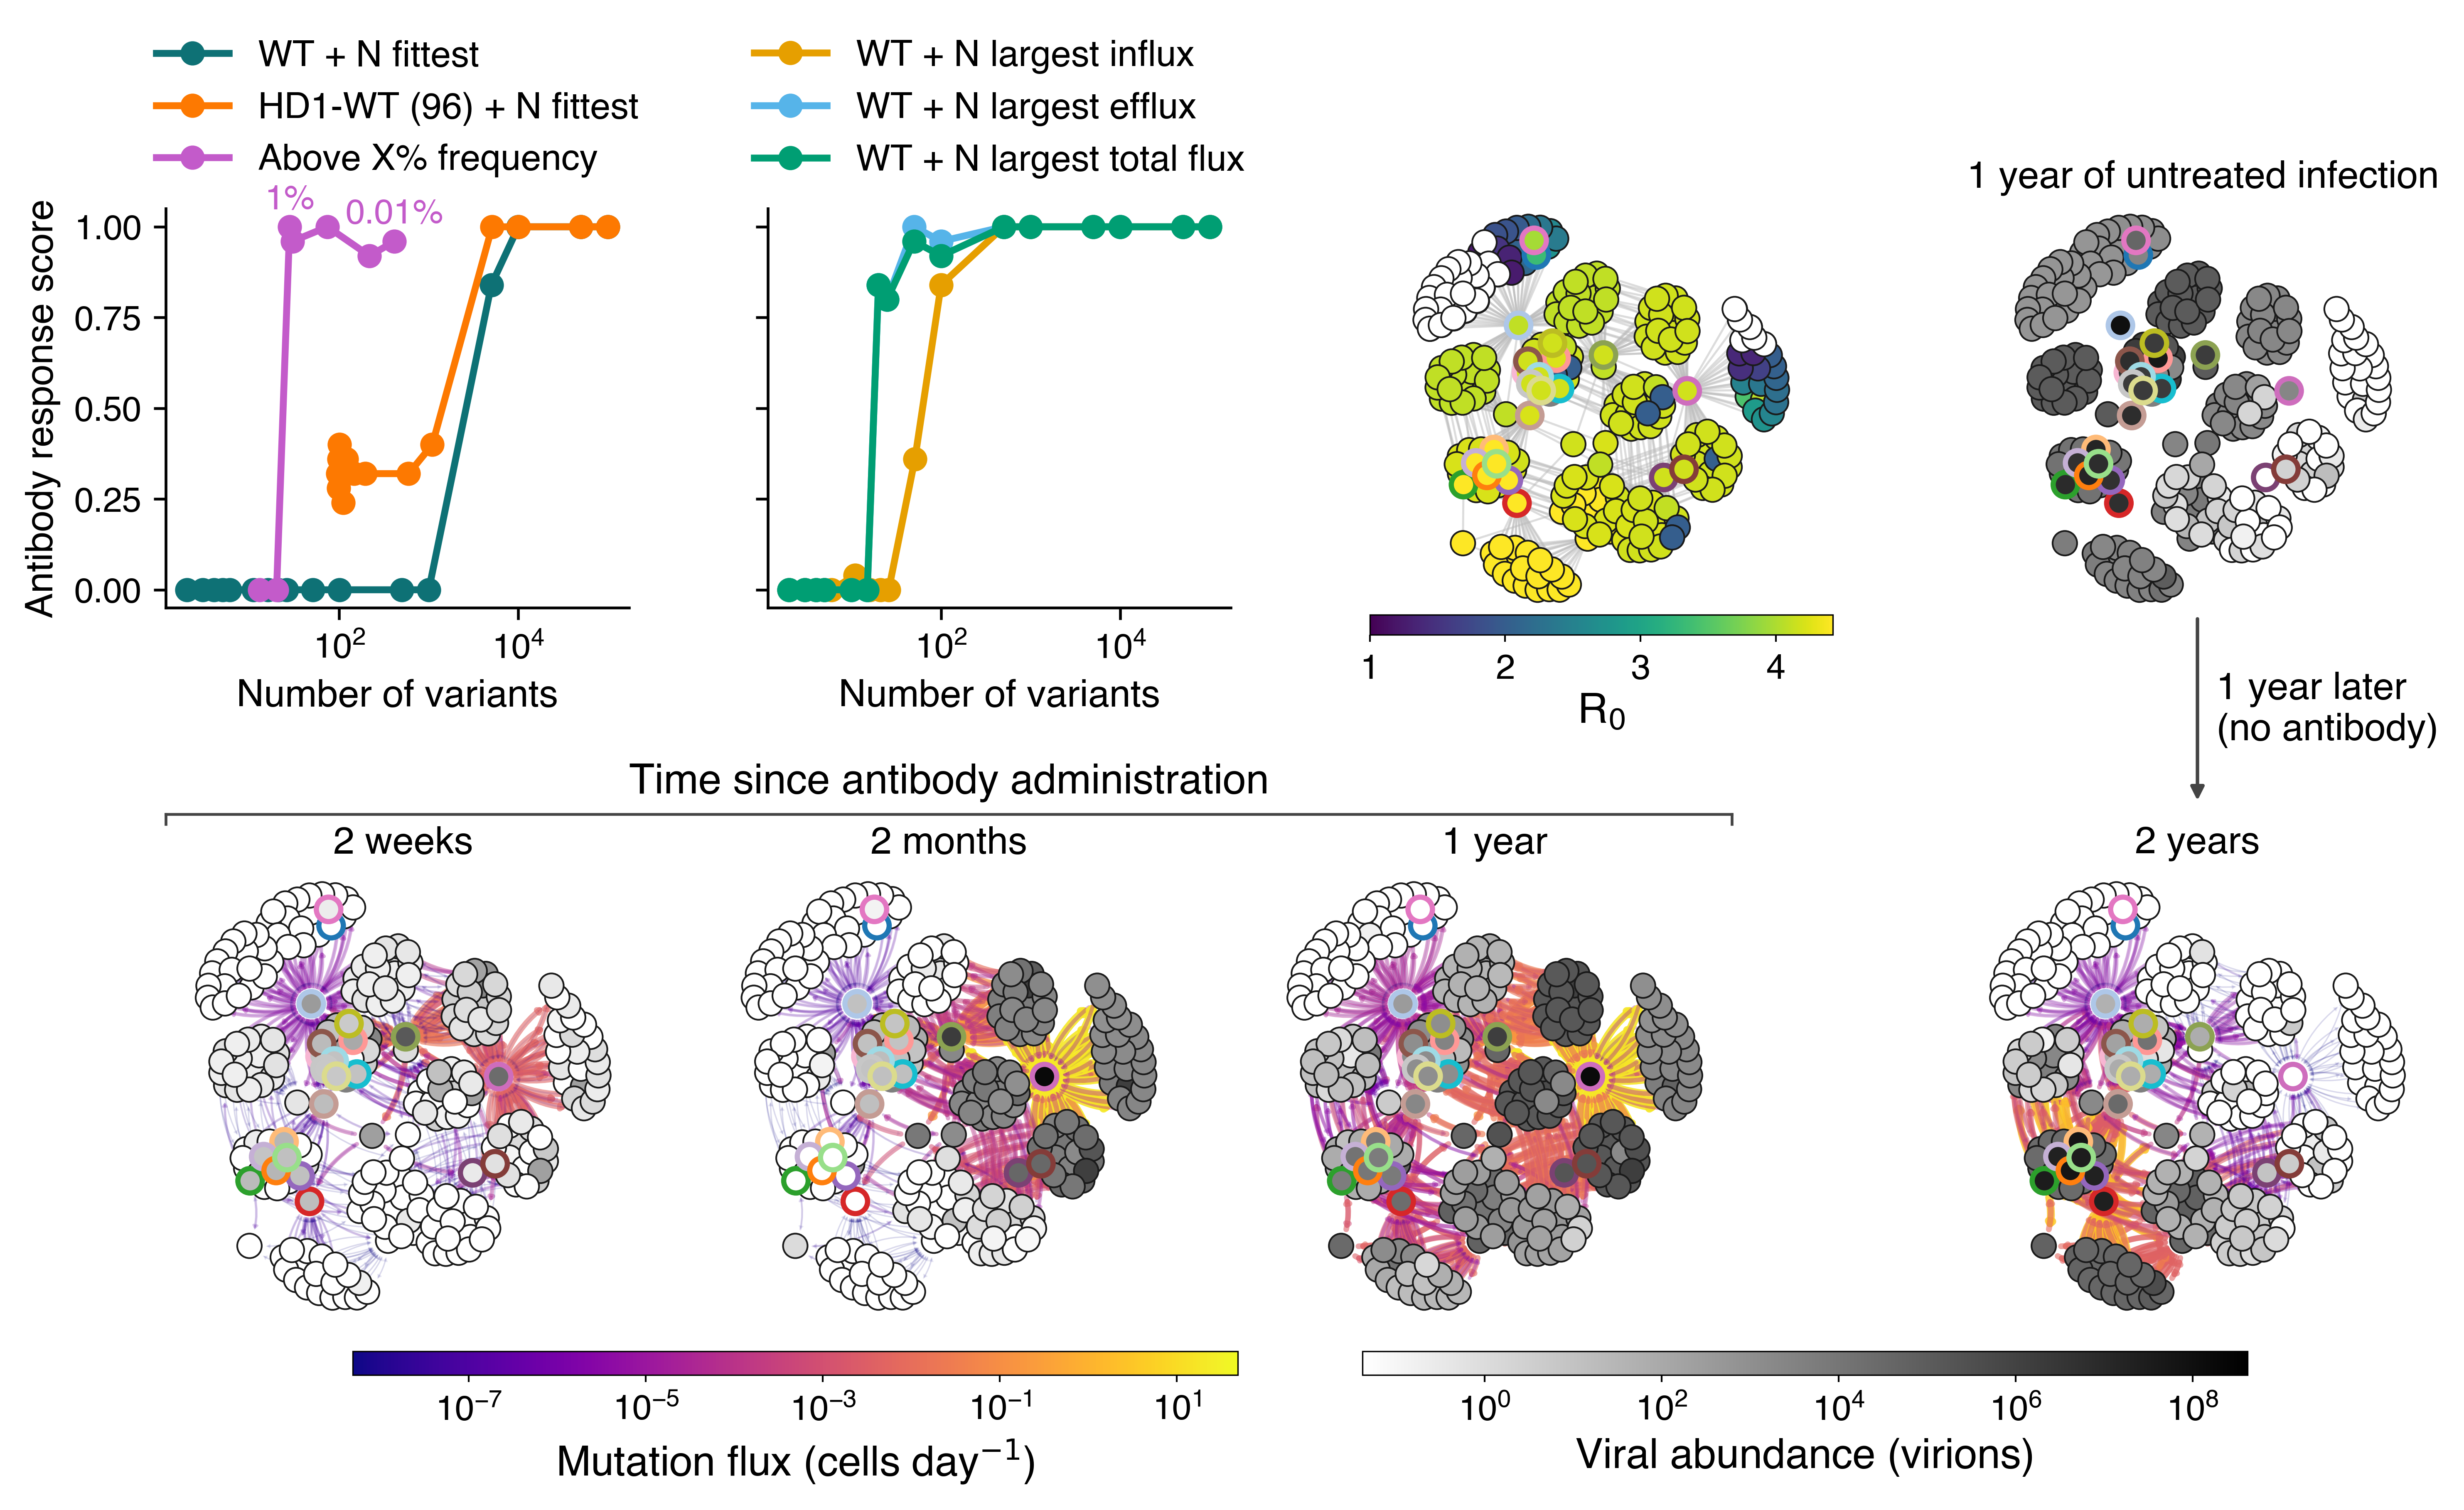

In [11]:
fig = plt.figure(figsize=(10, 5.35))
outer = GridSpec(4, 1, figure = fig, height_ratios = [1.8, 1.2, 2, 0.35], hspace = 0.0, left = 0.07, right = 0.98, top = 0.93, bottom = 0.04)
gs1 = GridSpecFromSubplotSpec(1, 4, subplot_spec = outer[0], wspace = 0.3)
gs2 = GridSpecFromSubplotSpec(1, 5, subplot_spec  = outer[2], width_ratios = [1, 1, 1, 0.18, 1], wspace = 0.18)

ax1 = fig.add_subplot(gs1[0, 0])
ax2 = fig.add_subplot(gs1[0, 1], sharey=ax1)
ax3 = fig.add_subplot(gs1[0, 2])
ax4 = fig.add_subplot(gs1[0, 3])
plt.setp(ax2.get_yticklabels(), visible=False)
ax5 = fig.add_subplot(gs2[0, 0])
ax6 = fig.add_subplot(gs2[0, 1])
ax7 = fig.add_subplot(gs2[0, 2])
ax8 = fig.add_subplot(gs2[0, 4])
  
#Panels 3A and 3B: dimensionality reduction scoring
plot_scores(results_remapped_clinic, ax=ax1, colors=['#0E7175', '#FD7901', '#C35BCA'], freq_labels={28: "1%", 414: "0.01%"})
plot_scores(results_remapped_quasispecies, ax=ax2, colors=['#E69F00', '#56B4E9', '#009E73'])
ax2.set_ylabel("")

#Panel 3C: Fitness
conditions = [
    {
        "edge_file": "../Simulation_data/WT_Ab/graph_outputs_trimmed/windowed_flux_time365_dose2p8e-06_seed8_compressed.csv",
        "node_file": "../Simulation_data/WT_Ab/graph_outputs_trimmed/windowed_nodes_time365_dose2p8e-06_seed8_compressed.csv",
         "ab_time": 365
    },
    {
        "edge_file": "../Simulation_data/WT_Ab/graph_outputs_trimmed/windowed_flux_time730_dose2p8e-06_seed8_compressed.csv",
        "node_file": "../Simulation_data/WT_Ab/graph_outputs_trimmed/windowed_nodes_time730_dose2p8e-06_seed8_compressed.csv",
        "ab_time": 730
    },
]
quasispecies_ab, quasispecies_no_ab = load_panel_data_shared_layout(conditions = conditions, top_nodes = "../Simulation_data/WT_Ab/graph_outputs_trimmed/top250.txt", norm_file = "../Simulation_data/WT_Ab/graph_outputs_trimmed/flux_norms.json")
 
fitness = FitnessPanelData(
    fitness_file = "../EvoEF_predictions/predictions_WT_Ab.csv",
    top_nodes = quasispecies_ab.top_nodes,
    wt_seq = "DIRQH",
    params = params,
    pos = quasispecies_ab.pos,
    fitness_cmap = "viridis",
)

annotation_dict = ex_colmap | after_color_map
front_nodes = list(annotation_dict.keys())
fitness.draw(ax3, show_colorbar=False, node_size=50, annotations=annotation_dict, front_nodes=annotation_dict)
pos_fit = ax3.get_position()
ax_cb_fit = fig.add_axes([pos_fit.x0, pos_fit.y0 - 0.02, pos_fit.width, 0.015])

r0_vals = [v for v in fitness._r0_vals if not np.isnan(v) and v >= 1.0]
fn = mcolors.Normalize(vmin=1.0, vmax=max(r0_vals))
sm = plt.cm.ScalarMappable(cmap = matplotlib.colormaps["viridis"], norm = fn)
sm.set_array([])
cb_fit = fig.colorbar(sm, cax=ax_cb_fit, orientation="horizontal")
cb_fit.set_label(f"R$_0$", fontsize=12, labelpad=2)
cb_fit.ax.tick_params(labelsize=10, length=2, width=0.5)
cb_fit.outline.set_linewidth(0.4)
ax_cb_fit.xaxis.set_label_position("bottom")
ax_cb_fit.xaxis.tick_bottom()

quasispecies_ab.draw(ax4, window_start=364, show_title=False, node_size=50, show_edges=False, annotations=annotation_dict, front_nodes=front_nodes)
ax4.set_title("1 year of untreated infection", fontsize=11)
quasispecies_ab.draw(ax5, window_start=379, show_title=False, node_size=50, annotations=annotation_dict, front_nodes=front_nodes)
ax5.set_title("2 weeks", fontsize=11)
quasispecies_ab.draw(ax6, window_start=425,show_title=False, node_size=50, annotations=annotation_dict, front_nodes=front_nodes)
ax6.set_title("2 months", fontsize=11)
quasispecies_ab.draw(ax7, window_start=729, show_title=False, node_size=50, annotations=annotation_dict, front_nodes=front_nodes)
ax7.set_title("1 year", fontsize=11)
quasispecies_no_ab.draw(ax8, window_start=729, show_title=False, node_size=50, annotations=annotation_dict, front_nodes=front_nodes)
ax8.set_title("2 years", fontsize=11)

#Labels
fig.canvas.draw()
pos_pretreatment = ax4.get_position()
pos_2wk = ax5.get_position()
pos_2yr = ax7.get_position()
pos_noab = ax8.get_position()

bracket_y = pos_2wk.y1 + 0.045
bracket_x0 = pos_2wk.x0
bracket_x1 = pos_2yr.x1
bracket_mid = (bracket_x0 + bracket_x1) / 2
bracket_tick = 0.0075
 
fig.add_artist(matplotlib.lines.Line2D([bracket_x0, bracket_x1], [bracket_y, bracket_y], transform=fig.transFigure, color="#444444", lw=0.8, clip_on=False))
fig.add_artist(matplotlib.lines.Line2D([bracket_x0, bracket_x0], [bracket_y - bracket_tick, bracket_y], transform=fig.transFigure, color="#444444", lw=0.8, clip_on=False))
fig.add_artist(matplotlib.lines.Line2D([bracket_x1, bracket_x1], [bracket_y - bracket_tick, bracket_y], transform=fig.transFigure, color="#444444", lw=0.8, clip_on=False))
fig.text(bracket_mid, bracket_y + 0.009, "Time since antibody administration", ha="center", va="bottom", fontsize=12, color="k", transform=fig.transFigure)

arrow_start = (pos_noab.x0 + pos_noab.width / 2, pos_pretreatment.y0 - 0.003)
arrow_end = (pos_noab.x0 + pos_noab.width / 2, pos_noab.y1 + 0.05)

fork_arrow = mpatches.FancyArrowPatch(arrow_start, arrow_end, transform=fig.transFigure, arrowstyle="-|>", mutation_scale=8, color="#444444", lw=1, linestyle="-", clip_on=False, zorder=10)
fig.add_artist(fork_arrow)
fig.text((arrow_start[0] + arrow_end[0]) / 2 + 0.0075, (arrow_start[1] + arrow_end[1]) / 2, "1 year later\n(no antibody)", transform=fig.transFigure, ha="left", va="center", fontsize=11, color="k")

#Colorbars
cb_top = outer[3].get_position(fig).y1 - 0.025
cb_height = 0.018
cb_gap = 0.05
cb_left = pos_2wk.x0 + 0.075
cb_right = pos_noab.x1 - 0.075
cb_mid = (cb_left + cb_right) / 2.0
 
ax_cb_flux = fig.add_axes([
    cb_left,
    cb_top - cb_height,
    (cb_mid - cb_left) - cb_gap / 2,
    cb_height,
])

ax_cb_abund = fig.add_axes([
    cb_mid + cb_gap / 2,
    cb_top - cb_height,
    (cb_right - cb_mid) - cb_gap / 2,
    cb_height,
])
 
sm_flux = plt.cm.ScalarMappable(cmap = quasispecies_ab.edge_cmap, norm = quasispecies_ab.flux_norm)
sm_flux.set_array([])
cb_flux = fig.colorbar(sm_flux, cax=ax_cb_flux, orientation="horizontal")
cb_flux.set_label("Mutation flux (cells day$^{-1}$)", fontsize=12, labelpad=3)
cb_flux.ax.tick_params(labelsize=10, length=2, width=0.5)
cb_flux.outline.set_linewidth(0.4)
 
sm_abund = plt.cm.ScalarMappable(cmap=plt.cm.gray_r, norm=quasispecies_ab.node_norm)
sm_abund.set_array([])
cb_abund = fig.colorbar(sm_abund, cax=ax_cb_abund, orientation="horizontal")
cb_abund.set_label("Viral abundance (virions)", fontsize=12, labelpad=3)
cb_abund.ax.tick_params(labelsize=10, length=2, width=0.5)
cb_abund.outline.set_linewidth(0.4)

fig.savefig('Fig3.png', dpi=600, bbox_inches="tight")

## Generate Fig. S4: dynamics after repeated antibody administration

In [12]:
def _remap_times(times, break_start, break_end):
    """Remap times to compress a break in the time axis."""
    remapped = np.empty_like(times, dtype=float)
    left = times <= break_start
    right = times >= break_end
    remapped[left] = times[left]
    remapped[right] = break_start + 10 + (times[right] - break_end)
    return remapped


def _draw_break_slashes(ax, x_break_display, y_min, y_max):
    """Draw slashes at x_break_display spanning [y_min, y_max]."""
    total_width = 10
    x_centers = [x_break_display - 10 / 2 + i * 10 for i in range(2)]
    y_mid = (y_min + y_max) / 2
    y_half = (y_max - y_min) / 2

    for xc in x_centers:
        ax.plot([xc, xc], [y_mid - y_half, y_mid + y_half], color='k', lw=1, solid_capstyle="round", transform=ax.transData, clip_on=False, zorder=10)


def stacked_frequency_plot_break(ax, totals_df, topk_df, sequences, color_map, classification=None, x_max=365, wt_seq='DIRQH', vl_mode=False, wt_legend=False, y_floor=-1, x_break=None):
    """Plot the frequencies of the top K variants with a break in the x-axis from break_stard to break_end."""
    times = np.sort(totals_df["time"].unique())
    totals_ts = totals_df.set_index("time").reindex(times)["sum_V"].fillna(0.0).to_numpy(float)
    n_seqs = len(sequences)
    pivot = _build_pivot(topk_df, times)
    freq_mat = _freq_matrix(pivot, sequences, totals_ts)

    if vl_mode:
        log_vl = np.where(totals_ts > 0, np.log10(totals_ts / 5000), np.nan)
        above_threshold = totals_ts >= 0.01
        log_vl_clipped = np.where(above_threshold, log_vl, np.nan)
        span = log_vl_clipped - y_floor
        weights = np.where(span > 0, span, np.nan)
        y_max = np.log10(3e5)
    else:
        weights = np.ones(len(times))
        y_max = 1.0

    stack = freq_mat * weights[np.newaxis, :]
    cum = np.nancumsum(stack, axis=0) if vl_mode else np.cumsum(stack, axis=0)
    base  = y_floor if vl_mode else 0.0
    bottoms = np.vstack([np.full(len(times), base), base + cum[:-1]])

    #Axis break
    use_break = x_break is not None
    if use_break:
        break_start, break_end = x_break
        keep = (times <= break_start) | (times >= break_end)
        times_plt = _remap_times(times[keep], break_start, break_end)
        x_max_plt = (break_start + 10 + (x_max - break_end) if x_max >= break_end else x_max)
        left_mask  = times[keep] <= break_start
        right_mask = times[keep] >= break_end

        def _fill_seg(ax, seg_mask, bot_arr, top_arr, color, **kw):
            t_seg = times_plt[seg_mask]
            bot_seg = bot_arr[keep][seg_mask]
            top_seg = top_arr[keep][seg_mask]
            if len(t_seg) >= 2:
                ax.fill_between(t_seg, bot_seg, top_seg, facecolor=color,
                                linewidth=0, **kw)
    else:
        times_plt = times
        x_max_plt = x_max

        def _fill_seg(ax, seg_mask, bot_arr, top_arr, color, **kw):
            ax.fill_between(times_plt[seg_mask], bot_arr[seg_mask], top_arr[seg_mask], facecolor=color, linewidth=0, **kw)

    labels = sequences + ["__others__"]
    for i, lbl in enumerate(labels):
        color = color_map.get(lbl, color_map["__others__"])
        bot_i = bottoms[i]
        top_i = bottoms[i] + stack[i]

        if use_break:
            for seg in (left_mask, right_mask):
                _fill_seg(ax, seg, bot_i, top_i, color)
        else:
            _fill_seg(ax, np.ones(len(times), dtype=bool), bot_i, top_i, color)

        #Hatching
        if i < n_seqs and classification and lbl in classification:
            cat = classification[lbl]
            hatch = ("////" if cat == "accessory" else "xxxx" if cat == "unique" else None)
            if hatch:
                if use_break:
                    for seg in (left_mask, right_mask):
                        _fill_seg(ax, seg, bot_i, top_i, "none", edgecolor="white", hatch=hatch, alpha=0.5)
                else:
                    _fill_seg(ax, np.ones(len(times), dtype=bool), bot_i, top_i, "none", edgecolor="white", hatch=hatch, alpha=0.5)

    if use_break:
        _shade_below_vl(ax, times_plt[left_mask],  totals_ts[keep][left_mask],  y_top=y_max)
        _shade_below_vl(ax, times_plt[right_mask], totals_ts[keep][right_mask], y_top=y_max)
    else:
        _shade_below_vl(ax, times, totals_ts, y_top=y_max)

    ax.set_xlim(times_plt.min(), x_max_plt)
    if use_break:
        _fix_break_ticks(ax, times, keep, left_mask, right_mask, times_plt, x_max_plt)

    if vl_mode:
        if use_break:
            ax.plot(times_plt[left_mask],  log_vl[keep][left_mask],  color="black", lw=1.5, zorder=8)
            ax.plot(times_plt[right_mask], log_vl[keep][right_mask], color="black", lw=1.5, zorder=8)
        else:
            ax.plot(times, log_vl, color="black", lw=1.5, zorder=8)

        y_ceil = int(np.ceil(y_max))
        ticks = list(range(y_floor, y_ceil + 1))
        ax.set_yticks(ticks)
        ax.set_yticklabels([f"$10^{{{t}}}$" for t in ticks])
        ax.set_ylim(y_floor, y_max)
        ax.set_ylabel("Viral Load (mL$^{-1}$)")
    else:
        ax.set_ylim(0, 1)
        ax.set_ylabel("Frequency")

    if use_break:
        x_slash = break_start + 5
        _draw_break_slashes(ax, x_slash, base, y_max)

    if wt_legend and wt_seq in sequences:
        import matplotlib.patches as mpatches
        ax.legend(
            handles=[mpatches.Patch(color=color_map[wt_seq], label=f"Wild type ({wt_seq})")],
            bbox_to_anchor=(0.5, 1.18), loc="upper center", frameon=False,
        )

def _fix_break_ticks(ax, times, keep, left_mask, right_mask, times_plt, x_max_plt):
    """Replace auto x-ticks with remapped times."""
    raw_ticks = ax.get_xticks()
    orig_kept = times[keep]
    remap_kept = times_plt

    new_tick_positions = []
    new_tick_labels = []

    for t in raw_ticks:
        if t < times_plt.min() or t > x_max_plt:
            continue

        idx = np.argmin(np.abs(remap_kept - t))
        orig_t  = orig_kept[idx]
        remap_t = remap_kept[idx]
        if np.abs(remap_kept[idx] - t) > 10:
            continue

        new_tick_positions.append(remap_t)
        new_tick_labels.append(f"{orig_t:.6g}")

    ax.set_xticks(new_tick_positions)
    ax.set_xticklabels(new_tick_labels)

def build_pre_post_topk_plot_break(ax, totals_df, topk_df, ab_time, global_seqs, global_color_map,
                             new_after_seqs, after_color_map, pre_window=10, post_window=50,
                             wt_seq='DIRQH', vl_mode=False, wt_legend=False, x_max=None,
                             ab_line_color="black", title=None, titlecolor='k', x_break=None, ab_time2=None):
    
    t_start = ab_time - pre_window
    t_end = ab_time + post_window
    totals_win = totals_df[(totals_df["time"] >= t_start) & (totals_df["time"] <= t_end)]
    topk_win   = topk_df[(topk_df["time"] >= t_start) & (topk_df["time"] <= t_end)]
    sequences = list(global_seqs) + list(new_after_seqs)
    color_map = dict(global_color_map)
    color_map.update(after_color_map)
    color_map.setdefault("__others__", "#ebebebf2")
    if x_max is None:
        x_max = t_end
    stacked_frequency_plot_break(ax, totals_win, topk_win, sequences, color_map, x_max=x_max, wt_seq=wt_seq, vl_mode=vl_mode, wt_legend=wt_legend, x_break=x_break)
    ax.set_title(title, color=titlecolor)

    def _remap_ab_time(t):
        if x_break is None:
            return t
        break_start, break_end = x_break
        if t <= break_start:
            return t
        if t >= break_end:
            return break_start + 10 + (t - break_end)
        return None 

    for t_ab in [ab_time, ab_time2]:
        if t_ab is None:
            continue
        t_plt = _remap_ab_time(t_ab)
        if t_plt is not None:
            ax.axvline(t_plt, color=ab_line_color, lw=1, ls="--", zorder=9)

In [13]:
#Generate colormap

def seed_from_fname(fname):
    m = re.search(r"seed(\d+)", fname)
    return int(m.group(1)) if m else None

def read_topk(path, common_times):
    kd = pd.read_csv(path)
    grouped = kd.groupby(["sequence", "time"], as_index=False)["V"].sum()
    pivot = grouped.pivot(index="sequence", columns="time", values="V").fillna(0.0)
    return pivot.reindex(columns=common_times, fill_value=0.0)

def compute_global_topk(topk_dfs, top_k=20):
    """Compute the global top-K sequences across runs by summing integrated viral loads per variant."""
    
    totals = {}
    for df in topk_dfs:
        for seq, area in _integrated_V(df).items():
            totals[seq] = totals.get(seq, 0.0) + area
    return [s for s, _ in sorted(totals.items(), key=lambda x: x[1], reverse=True)[:top_k]]

def reconcile_color_map(color_map, reference_color_map):
    """Override colors to match reference_color_map for any sequence present in both (to match Fig. S1 colors with Fig. 1)"""
    final = dict(color_map)
    color_to_seq = {c: s for s, c in final.items()}
    overrides = {s: c for s, c in reference_color_map.items() if s in final}

    for seq, target_color in overrides.items():
        current_color = final[seq]
        if current_color == target_color:
            continue
        rep = color_to_seq.get(target_color)

        final[seq] = target_color
        color_to_seq[target_color] = seq

        if rep is not None:
            final[rep] = current_color
            color_to_seq[current_color] = rep
        else:
            color_to_seq.pop(current_color, None)

    return final

base_dir = "../Simulation_data/No_Ab/sim_outputs"
topk_files = sorted(glob.glob(f"{base_dir}/topk_noAb_seed*.csv"))
topk_by_seed = {seed_from_fname(f): f for f in topk_files}
seeds = sorted(set(topk_by_seed))

topk_dfs = []
for i, s in enumerate(seeds):
    topk_path = topk_by_seed[s]
    topk_dfs.append(pd.read_csv(topk_path))

global_topk = compute_global_topk(topk_dfs, top_k=40)
colmap = build_color_map(global_topk)
colmap = reconcile_color_map(colmap, ex_colmap)

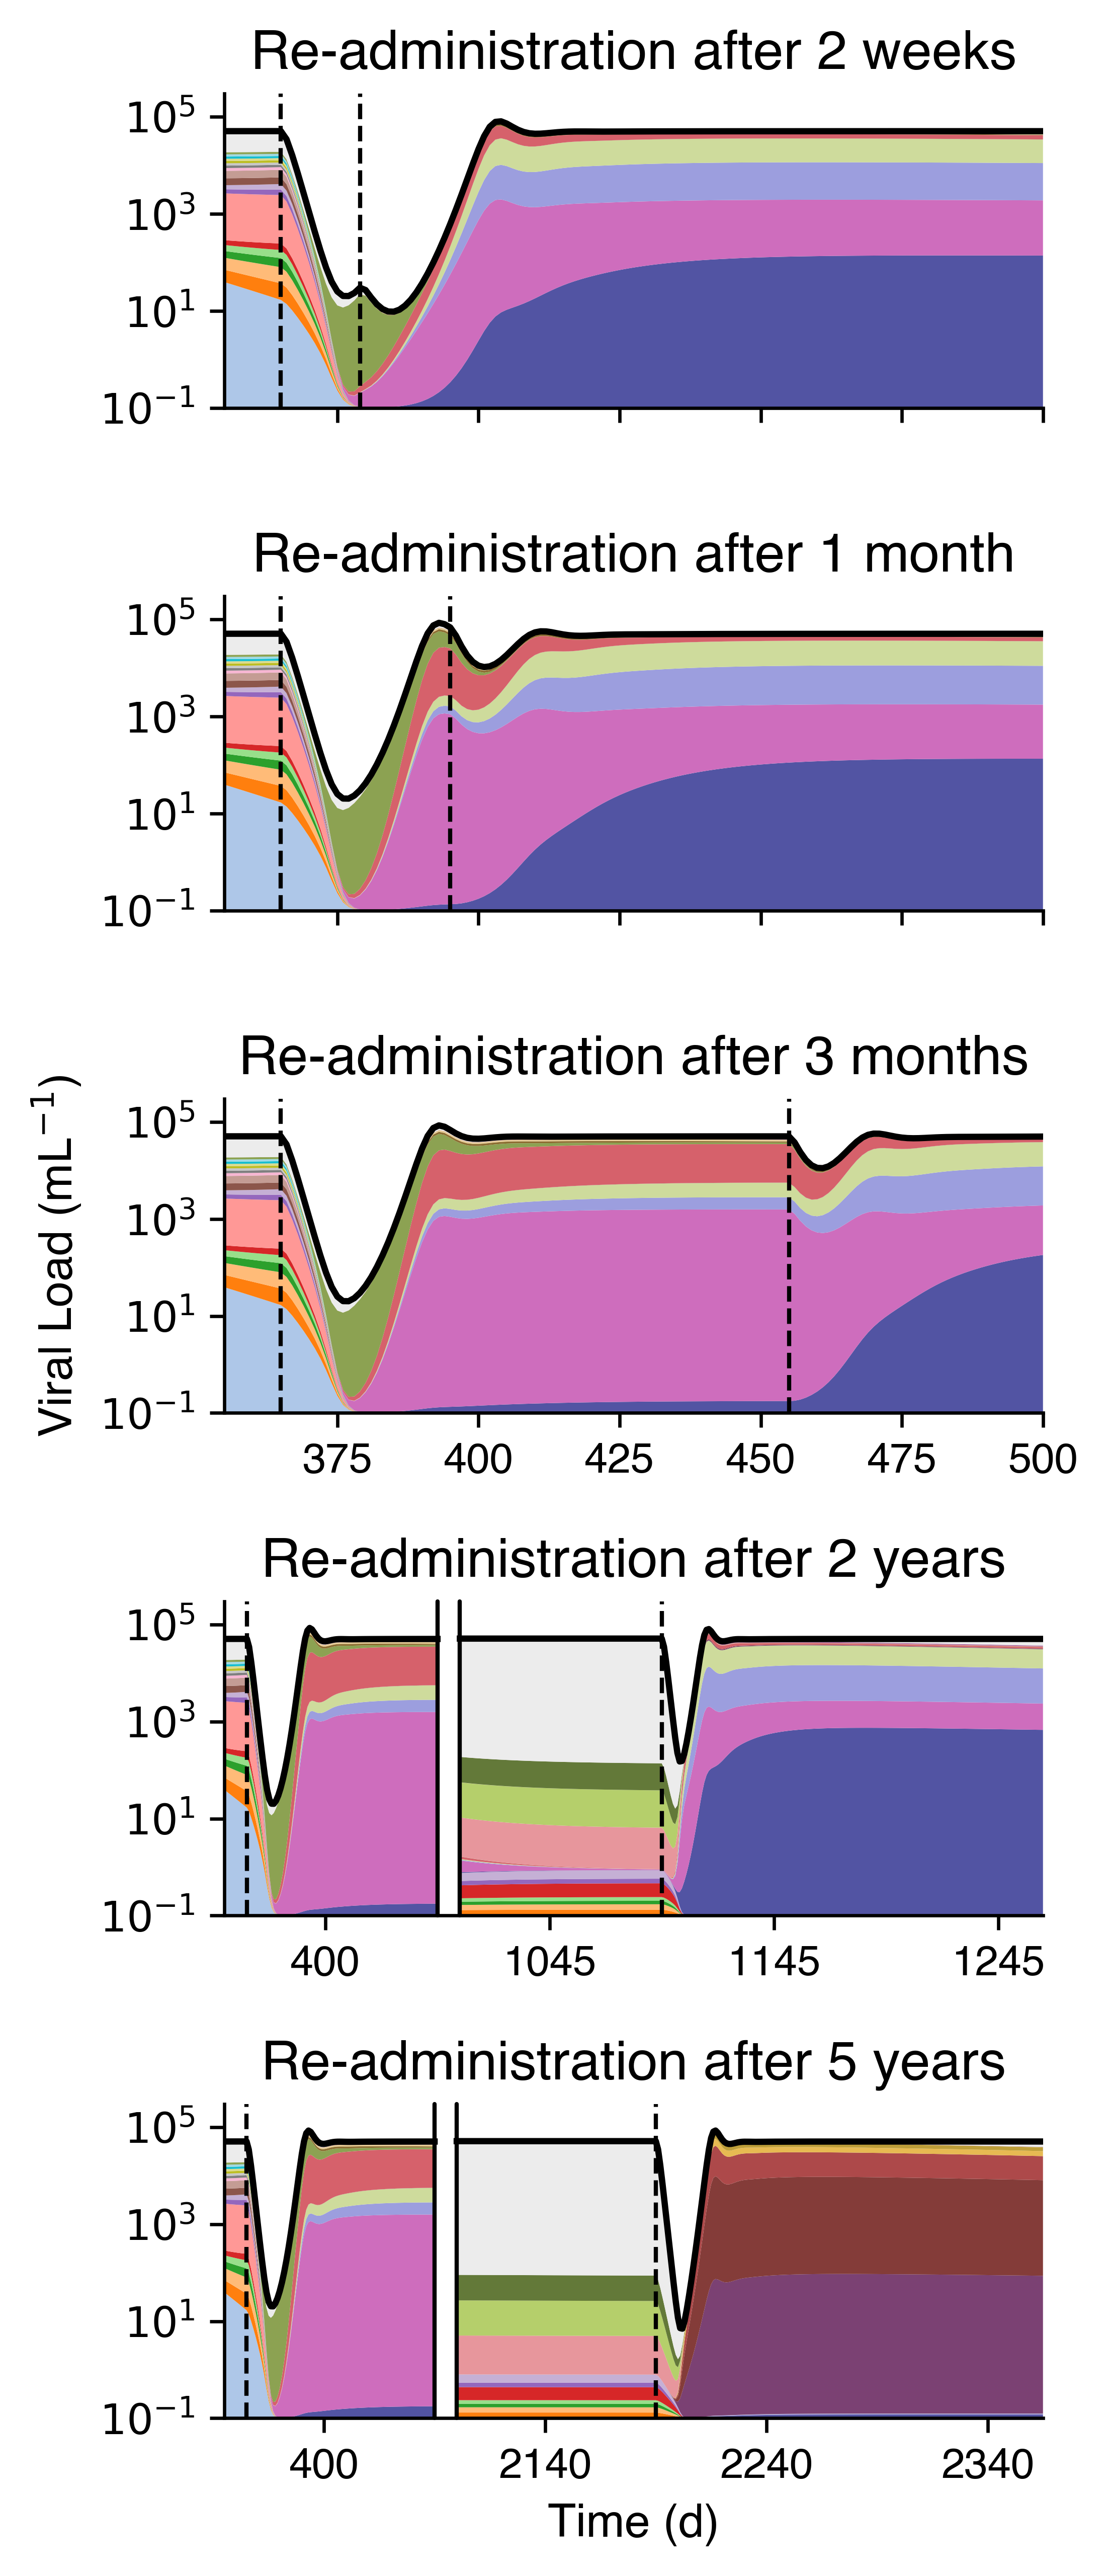

In [14]:
fig, axes = plt.subplots(5, 1, figsize=(3.5, 10), constrained_layout=False)
axes = axes.flatten()
fig.subplots_adjust(hspace=0.6)

base_dir = "../Simulation_data/WT_Ab/sim_outputs_biphasic_repeated_doses"
totals_readmin_2weeks = pd.read_csv(base_dir+'/totals_time365_379_dose2p8e-06_seed8.csv')
topk_readmin_2weeks = pd.read_csv(base_dir+'/topk_time365_379_dose2p8e-06_seed8.csv')
totals_readmin_1month = pd.read_csv(base_dir+'/totals_time365_395_dose2p8e-06_seed8.csv')
topk_readmin_1month = pd.read_csv(base_dir+'/topk_time365_395_dose2p8e-06_seed8.csv')
totals_readmin_3months = pd.read_csv(base_dir+'/totals_time365_455_dose2p8e-06_seed8.csv')
topk_readmin_3months = pd.read_csv(base_dir+'/topk_time365_455_dose2p8e-06_seed8.csv')
totals_readmin_2years = pd.read_csv(base_dir+'/totals_time365_1095_dose2p8e-06_seed8.csv')
topk_readmin_2years = pd.read_csv(base_dir+'/topk_time365_1095_dose2p8e-06_seed8.csv')
totals_readmin_5years = pd.read_csv(base_dir+'/totals_time365_2190_dose2p8e-06_seed8.csv')
topk_readmin_5years = pd.read_csv(base_dir+'/topk_time365_2190_dose2p8e-06_seed8.csv')

readmin_after_seqs, readmin_color_map = compute_shared_after_topk(
    [topk_readmin_2weeks[topk_readmin_2weeks["time"].between(365, 445)],
     topk_readmin_1month[topk_readmin_1month["time"].between(365, 445)],
     topk_readmin_3months[topk_readmin_3months["time"].between(545, 595)],
     topk_readmin_2years[topk_readmin_2years["time"].between(1095, 1145)],
     topk_readmin_5years[topk_readmin_5years["time"].between(2190, 2240)],
    ], topk_seqs, top_k_after=20, after_palette="tab20b_r", global_color_map=colmap)

readmin_color_map = reconcile_color_map(readmin_color_map, after_color_map)

build_pre_post_topk_plot(axes[0], totals_readmin_2weeks, topk_readmin_2weeks, 365, topk_seqs, colmap, readmin_after_seqs, readmin_color_map, vl_mode=True, ab_time2=379, post_window=135)
axes[0].set_xticklabels([])
axes[0].set_ylabel("")
axes[0].set_title("Re-administration after 2 weeks", fontsize=13)
build_pre_post_topk_plot(axes[1], totals_readmin_1month, topk_readmin_1month, 365, topk_seqs, colmap, readmin_after_seqs, readmin_color_map, vl_mode=True, ab_time2=395, post_window=135)
axes[1].set_xticklabels([])
axes[1].set_ylabel("")
axes[1].set_title("Re-administration after 1 month", fontsize=13)
build_pre_post_topk_plot(axes[2], totals_readmin_3months, topk_readmin_3months, 365, topk_seqs, colmap, readmin_after_seqs, readmin_color_map, vl_mode=True, ab_time2=455, post_window=135)
axes[2].set_title("Re-administration after 3 months", fontsize=13)
build_pre_post_topk_plot_break(axes[3], totals_readmin_2years, topk_readmin_2years, 365, topk_seqs, colmap, readmin_after_seqs, readmin_color_map, vl_mode=True, ab_time2=1095, post_window=900, x_break=(450,1005))
axes[3].set_ylabel("")
axes[3].set_title("Re-administration after 2 years", fontsize=13)
build_pre_post_topk_plot_break(axes[4], totals_readmin_5years, topk_readmin_5years, 365, topk_seqs, colmap, readmin_after_seqs, readmin_color_map, vl_mode=True, ab_time2=2190, post_window=2000, x_break=(450,2100))
axes[4].set_ylabel("")
axes[4].set_xlabel("Time (d)")
axes[4].set_title("Re-administration after 5 years", fontsize=13)

for a in axes:
    a.set_yticks([-1, 1, 3, 5])

plt.savefig('FigS4', dpi=600, bbox_inches='tight')